# Digital Twin Integration
by Chris Mimra (UniSQ) 2026

This notebook serves as Software Requirement Document and code-illustration of the scientifically relevant software parts. It is produced by a human who takes full responsibility. The production system is developed in parallel by an AI agent based on the criteria in this notebook. The scientifically non-relevant parts are called from the AI-generated libraries from the production environment. The software is transferred to a Windows workstation. The polarisation camera and a touch monitor are connected to it.

## How we work

The process follows Matt Pocock's coding workflow. This notebook replaces GitHub issues.
1. **Grill-me on the whole plan** to reach a shared understanding of the system and of the interfaces between slices.
2. **Per slice (sections 0–7):** a grill-me on the implementation, then a **Specs** subsection, then a **Tickets** subsection with bullet points, then implementation. Each ticket is deleted once it is implemented, and the Tickets subsection is deleted when it is empty. The Specs subsection stays as the record of the slice.
3. **Validation** uses tests (pytest) and a CI check that runs locally (`uv run python tools/ci.py`), because GitHub automations are not available. Tests run on **synthetic data** with a known answer, because no existing dataset contains matching calibration and tow data. The generator lives in `src/synthetic_data/` (git-ignored, not part of the notebook). It creates **one** committed dataset per mandrel (cylinder, banana); all tests use these datasets, so a fresh clone does not need the generator.
4. **Scientific code is written in the notebook.** Production copies these functions, and a reference test checks that the production code gives the same results as the notebook on the same synthetic data.
5. **Keep it slim.** Decisions that are critical for understanding the system, or for its scientific value, go into the main sections. Other implementation decisions go into section 9 and are deleted from there once they are implemented.

## General software structure

The monitoring system consists of 7 slices. Each slice reads and writes files only, so every slice can be run on its own in the notebook or in production. Each run has one **run folder** holding `run.json` (run ID, references to the calibration bundle and tow file, camera settings, processing settings (DoLP threshold, incidence limit), tow width, frame log) and the files of all slices, named by revolution index. The calibration bundle has its own folder, and a run refers to it. The first version processes a finished run offline. Each tow is evaluated on its own; layers play no role.

| # | Slice | Runs | Notebook | Consumes | Produces |
| - | ----- | ---- | -------- | -------- | -------- |
| 1 | Preview | Live | No | Camera stream | Camera settings (gain, exposure, save location) |
| 2 | Calibration | Per installation | No | Checkerboard images, empty-mandrel images, mandrel STEP, crop polygon drawn by the user | Calibration bundle |
| 3 | Data capturing | Per run | No | Camera settings, trigger pulses | Reference frame of the empty mandrel, raw frames (one per revolution), frame log (timestamp per frame) |
| 4 | Conversion | Per frame | Yes | Raw frame, polariser pattern | S0, S1, S2, DoLP, AoLP |
| 5 | Mapping | Per frame | Yes | Polarisation maps, calibration bundle, processing settings | Per pixel: 3D point, surface normal (once per run), fibre angle (NaN where invalid); flattened image |
| 6 | Tow matching | Per frame | Yes | Mapped frames *k−1* and *k*, planned path | Table per revolution and visible crossing (planned position and angle, Δ position, Δ angle; "not visible" if none), overlay image |
| 7 | Data export | Per run | Yes | Outputs of 2–6 | Tow table (CSV) and mapped arrays; the 3DEXPERIENCE adapter comes later |

### Shared conventions
- One coordinate frame, the origin of the mandrel STEP file. Units are mm and degrees.
- Image angles (AoLP, `polar_pattern`) are measured from the image +x axis (columns, to the right) towards +y (rows, downwards), in (−90°, 90°].
- The mandrel enters the system as a triangle mesh in the STEP frame, converted once during calibration. Its rotation axis (a point and a direction) is entered with the STEP file and checked during calibration.
- The fibre angle lies in (−90°, 90°]. It is measured in the local surface plane from the mandrel axis direction, positive towards the surface direction of mandrel rotation. Planned and measured angles use the same definition.
- The planned path and the mesh share the STEP frame. Path points further than one tow width from the mesh (lead-in and lead-out) are ignored.
- The trigger pin fires exactly one frame per revolution at a fixed mandrel angle, and the camera does not move during a run. All frames of a run therefore share the same pixel-to-surface geometry, which is computed once per part. Motion blur and trigger jitter are treated as uncertainty, not corrected.
- A frame is identified by run ID and revolution index. Revolution indices come from the frame timestamps divided by the nominal period, not from counting frames, so pin bounces and missed pulses do not shift the count.
- **Touch-down model:** the tow lands on the mandrel at a constant machine angle φ_touch. Each planned-path point gets its unwrapped body angle φ around the mandrel axis (counter-clockwise about the oriented axis, zero at the STEP X direction). A point touches down when mandrel angle + φ = φ_touch, so later tow lies at smaller φ. The mandrel angle when laid is θ = θ₀ + (φ₀ − φ), with θ₀ = (φ_touch − φ₀ − pin phase) mod 360° for the first point, and the point lies in revolution k = floor(θ / 360°). This requires the mandrel to turn in one direction only. The free fibre length between the payout eye and the mandrel is ignored.
- **Measured tow:** because all frames share the same geometry, the tow laid in revolution *k* is the set of pixels whose AoLP or DoLP changed significantly between frames *k−1* and *k*. For *k = 0* the reference frame of the empty mandrel is used.

Implementation order: forward model (section 5) → synthetic dataset (section 0, cylinder) → 4 Conversion → 5 Mapping with forward model, then the banana dataset → 6, 7 → production-only 3, 1, 2. The calibration bundle is synthetic until slice 2 exists.

### Glossary
- **Run**: the winding of one part, from *record* to *stop*. One run folder.
- **Revolution**: one full turn of the mandrel, counted from the trigger pin. Indexed *k*.
- **Frame**: one raw image, captured once per revolution by the pin. Frame *k* belongs to revolution *k*. The **reference frame** shows the empty mandrel before winding.
- **Tow**: the band laid during one revolution. It is the unit of evaluation.
- **Pin phase**: the mandrel angle at which a frame is exposed, in the STEP frame, including the trigger delay.
- **Touch-down angle (φ_touch)**: the constant machine angle at which the tow first touches the mandrel.
- **Calibration bundle**: intrinsics, distortion, image size, camera pose, mandrel axis, pin phase, touch-down angle and mandrel mesh of one installation. It stays valid until the camera is moved.
- **Planned path**: the tow centre line from the tow placement file (CSV of points X, Y, Z in mm). **Planned tow**: the band of tow width around it. **As-laid path**: the path the tow actually took (known only in synthetic data).
- **Polarisation maps**: S0, DoLP and AoLP of one frame, per super-pixel (output of Conversion).
- **Crop polygon**: the image region that shows only mandrel and tows, drawn during calibration. Pixels outside it are discarded.
- **Valid pixel**: a pixel inside the crop polygon whose ray hits the mandrel within the incidence limit and whose DoLP is at least the DoLP threshold. Only valid pixels get a fibre angle.
- **Flattened image**: the mandrel surface unrolled onto a plane (axial position × arc length r_ref·φ), at 0.1 mm per pixel.
- **Crossing point**: where a revolution's planned path crosses the plane through the camera centre and the mandrel axis, on the camera side. A revolution is **visible** if its crossing point lies inside the crop polygon within the incidence limit.
- **Export package**: the folder a processed run hands to the digital thread: tow table, run metadata and conventions, flattened arrays and overlays per revolution.
- **Marker table**: the ArUco markers on the empty mandrel: marker ID and centre in the STEP frame (mm); corners follow from size, surface normal and the orientation rule.
- **Capture station**: the computer at the winder that the camera is plugged into (a Raspberry Pi). The operator uses only this station. Not to be confused with the recorder, the part that writes a run.
- **Processing station**: the workstation that stores all data, solves calibrations and processes runs. It is started once and needs no operator input.
- **Job**: a calibration step or a finished run that the capture station hands over, through the shared folder, for the processing station to solve or process.
- **Fibre angle**: the angle between the fibre direction and the mandrel axis, in the local surface plane, in (−90°, 90°].

## 0 Synthetic dataset

Production-only tooling, not part of the notebook's scientific code. A generator in `src/synthetic_data/` (git-ignored) creates **one** dataset per mandrel, which is committed. All tests and the notebook examples use it. It contains `demoData/synthetic/cylinder/` (from `WindingDummieSym.step`, helical path) and `demoData/synthetic/banana/` (from `Banana 1.STEP` and `planned_Path.csv`, revolution 1 not visible). Each holds a calibration bundle and a run folder with a reference frame and 3 revolutions at full resolution, stored compressed.

- **Camera:** acA4112-30umPOL (3.45 µm pixels) with the AIAC22 16 mm lens, 700 mm from the mandrel axis, optical axis perpendicular to the mandrel axis through the middle of the part, radial distortion k1 = −0.05.
- **Cylinder:** axis = Z through the origin, winding surface r = 125 mm between z = −185 and 185 mm (rounded ends beyond). Path: one helical pass over z = −180…180 mm in 3 revolutions (fibre angle ≈ −81°). With touch-down 180° and pin phase 0°, each tow crosses the view once, at z = −120, 0 and 120 mm. Size: 83 MB.
- **Banana:** axis = Y through the origin, defined by the rod. The STEP file and `planned_Path.csv` already share this frame. The mesh holds both banana halves and the visible rod sections; dowels and inner tube are left out. The banana spans y = −100…700 mm and bulges towards −Z; the camera sits at (0, 250, −700), facing the bulge and aimed at the axis, image +x along +Y. The path passes the camera only once per revolution (at y ≈ 285, 679, 210, 17, 650 mm), so not every revolution can be seen: the camera is 50 mm below the middle so that the passes at y ≈ 285 and 210 lie inside the view, and the banana run uses an **incidence limit of 30°** (processing setting in its `run.json`; the cylinder keeps 20°). Path revolutions 0–2 are used; the path runs back and forth along the axis and is coarse (segments up to 41 mm), so the generator resamples it at 1 mm on the mesh for rendering, while the run folder keeps the original CSV. The touch-down angle is chosen by the generator (pin phase fixed at 0°; only their difference matters) so that tows 0 and 2 cross the plane through camera and axis inside the crop polygon within the incidence limit, and tow 1 outside it (a **not visible** revolution, as slice 6 must report); the generator stops if that is impossible. `truth.json` marks each revolution as visible or not. The crop polygon is the outline of the mandrel pixels within the incidence limit, at most 8 corners.
- **Calibration images** (for slice 2): `demoData/synthetic/calibration_images/` with 12 S0 images of the 10×7 checkerboard (40 mm tiles) at different poses, and 5 S0 images of the empty banana at the pin pulse with the ArUco markers of `demoData/marker_locations.csv` (30 mm) rendered on the mesh by ray casting, so markers bent around the mandrel are exact; 4 × 4 rays per super-pixel. Markers 9, 10, 19, 20 and 21 lie in the view (8 just outside). Stored as 8-bit PNG with noise, about 9 MB. The true intrinsics and pose are those of the banana calibration bundle.
- **Ground truth:** an **as-laid path** = planned path with, per revolution, a lateral offset d_k ∈ ±2 mm (in the surface, perpendicular to the path) and an angle error δ_k ∈ ±1° (rotation about the crossing point, where the path crosses the plane through the camera centre and the mandrel axis), fixed seed. Revolution 0 has zero error.
- **Rendering:** forward model (section 5), polariser pattern, shot noise, 12-bit quantisation, low-DoLP background, a fixed random AoLP per pixel on bare mandrel and background (so only a new tow changes between frames), earlier tows under the new one. Motion blur, specular highlights and vignetting are left out.

### Specs

**Problem.** No dataset exists with matching calibration, frames, planned path and known deviations, so no slice can be tested against a known answer.

**Solution.** A one-off generator writes a complete, committed dataset for both mandrels in exactly the file format that the production slices read and write. A fresh clone needs only the dataset.

**User stories**
1. As the researcher, I want a dataset with known fibre angles and tow deviations, so that every slice can be tested against a true answer.
2. As the researcher, I want the dataset in the same file format as a real run, so that the notebook and production read synthetic and real runs identically.
3. As the researcher, I want a symmetric and an asymmetric mandrel, so that Mapping is tested beyond analytic surfaces.
4. As the researcher, I want frames rendered with the notebook's forward model, so that the synthetic AoLP follows the model I take responsibility for.
5. As the researcher, I want revolution 0 laid without error, so that a method that reports deviations where there are none is caught.
6. As the researcher, I want a reference frame of the empty mandrel, so that the measured tow of revolution 0 can be found.
7. As the researcher, I want earlier tows to stay visible under the new one, so that the change between frames *k−1* and *k* is tested realistically.
8. As the researcher, I want realistic noise and 12-bit raw values, so that Conversion and the change detection see camera-like data.
9. As the developer, I want the dataset generated once and committed, so that tests are deterministic and need no generator.
10. As the developer, I want one loader for calibration bundles and run folders, so that every slice uses the same file interface.
11. As the developer, I want per-pixel ground-truth geometry and fibre angles, so that Mapping can be tested pixel by pixel.

**Implementation decisions**
- **Forward model module** (`digital_thread`): the section 5 functions, written in the notebook and copied into the package: local fibre frame, fibre angle → AoLP, AoLP → fibre angle, plus rendering of S0 and DoLP. The generator imports it from the package.
- **Dataset I/O module** (`digital_thread`): reads and writes the calibration bundle and the run folder. This is the one interface every slice uses.
- **Calibration bundle** = `calibration.json` + `mesh.npz` (vertices, faces and outward CAD normals per vertex, STEP frame, mm). The JSON holds: image size and intrinsics K of the **super-pixel image** (2048×1500, the resolution of S0/DoLP/AoLP), distortion coefficients in OpenCV order, camera pose as R and t with x_cam = R·X + t, mandrel axis (point, direction oriented by the right-hand rule with the mandrel rotation), pin phase, touch-down angle.
- **Run folder** = `run.json` + frames. The JSON holds: run ID, relative path to the calibration bundle, tow file name, tow width (6.35 mm), polariser pattern, camera settings, nominal period, and the frame log (file name and timestamp per frame, including the reference frame). Raw frames are compressed `.npz` (key `raw`, uint16, 3000×4096), named `reference_raw.npz` and `rev000_raw.npz`, `rev001_raw.npz`, … Production capture uses the same format. The planned path is copied into the run folder in the demo CSV format.
- **Ground truth** (synthetic runs only): `truth.json` (d_k, δ_k, crossing point per revolution, seed), `as_laid_path.csv`, `truth_geometry.npz` (3D point and normal per super-pixel, NaN off the mandrel), and `revNNN_truth.npz` (true fibre angle and revolution of the top tow per super-pixel; NaN / −1 where no tow is visible).
- **Revolution assignment** in the generator uses the touch-down model from *Shared conventions*, with pin phase and φ_touch written to the calibration bundle, so slice 6 assigns the same tows to the same revolutions.
- **Rendering:** one ray per super-pixel, cast once per mandrel, since the geometry is the same for all frames. The 4 polariser pixels of a super-pixel share that ray, and I_θ = S0/2 · (1 + DoLP · cos 2(ψ − θ)). Coverage: a surface point belongs to tow k if it lies within half a tow width of the as-laid centre line of revolution k; the newest tow is on top. The fibre direction is the local tangent of that centre line, projected into the tangent plane. Shot noise is Poisson at about 10 500 e⁻ full well; values are quantised and clipped to 0…4095.
- **Timestamps:** nominal period 12 s (≈ 0.083 rev/s); the reference frame is one period before revolution 0. The dataset contains no bounces or missed pulses.
- **Generator** (`src/synthetic_data/`, git-ignored): STEP → mesh (gmsh), camera rays with distortion (fixed-point inversion of the OpenCV distortion model), ray casting (Open3D), path perturbation, rendering, writing through the dataset I/O module. It is not tested itself; the committed dataset is.

**Testing decisions**
- Tests check external behaviour only, through two seams: the **dataset I/O module** (loading the committed dataset) and the **forward model module**.
- Dataset tests: both mandrels load completely; image sizes agree between bundle and frames; raw values are uint16 ≤ 4095; timestamps rise by about one period; revolution 0 has zero error and all d_k, δ_k are within bounds; every visible revolution's tow crosses the view (true fibre angle present in `revNNN_truth.npz`).
- Forward model tests: AoLP → fibre angle inverts fibre angle → AoLP over random geometry within the incidence limit; a hand-checked case (camera square to the cylinder, fibre along the axis) gives the expected AoLP.
- Reference test: the package forward model gives the same results as the notebook's section 5 code on fixed inputs.
- Prior art: none yet; pytest and ruff are configured in `pyproject.toml`.

**Out of scope:** motion blur, specular highlights, vignetting, pin bounces and missed pulses in the data, calibration images (checkerboard), more than 3 revolutions, physical validation.

**Further notes.** The dataset is regenerated whenever the forward model changes. New dependencies (gmsh, Open3D, SciPy; uv group `generator`) are for the generator; whether Open3D also serves Mapping in production is decided in the slice 5 grill.

### Specs: banana dataset (T5)

**Problem.** The cylinder only tests analytic geometry: constant radius, normals perpendicular to the axis, one helical pass. Mapping's inverse forward model, the touch-down model and the change detection are untested on a surface whose normal tilts along the axis, whose body lies off the axis, and whose path runs back and forth.

**Solution.** The generator produces a second committed dataset from `Banana 1.STEP` and `planned_Path.csv`, in the same format as the cylinder, and the dataset tests plus an end-to-end Mapping check run on it.

**User stories**
1. As the researcher, I want a synthetic run on the asymmetric banana, so that Mapping is tested where normals tilt along the axis.
2. As the researcher, I want the real tow placement file as the planned path, so that the dataset carries its real coarseness and back-and-forth winding.
3. As the researcher, I want the camera centred on the banana's middle and facing its bulge, so that the view resembles the planned physical validation.
4. As the researcher, I want tows 0 and 2 to cross the view inside the crop polygon within the incidence limit and tow 1 outside it, so that both an evaluable and a not-visible revolution are tested.
5. As the researcher, I want the generator to stop if no touch-down angle and pin phase achieve this, so that a revolution is never dropped silently.
6. As the researcher, I want the tow rendered from a path resampled on the mesh, so that coarse chords do not sink the tow below the surface.
7. As the researcher, I want the run folder to hold the original planned path, so that Tow matching receives the input a real run would give it.
8. As the researcher, I want the crop polygon derived from the incidence limit, so that the valid region is the region Mapping can evaluate.
9. As the researcher, I want the fibre angle recovered on the banana within the same bias as on the cylinder, so that the inverse forward model is shown to work beyond analytic surfaces.
10. As the developer, I want the shape-independent dataset tests to run on both mandrels, so that the banana dataset meets the same contract.
11. As the developer, I want cylinder-only tests clearly separated, so that analytic expectations are never applied to the banana.

**Implementation decisions**
- **Generator** (git-ignored): a banana entry next to the cylinder. Mesh: both banana halves plus the visible rod sections; dowels and the inner tube left out. Axis: point at the origin, direction Y, oriented so the body angle decreases along the path. Camera at (0, 250, −700), aimed at (0, 250, 0), image +x along +Y; incidence limit 30° in the run's processing settings. Path: `planned_Path.csv`, points further than one tow width from the mesh dropped, revolutions 0–2 kept.
- **Resampling:** for the as-laid path and the coverage, the path is resampled at 1 mm and projected onto the mesh. `planned_path.csv` in the run folder is the original file restricted to revolutions 0–2.
- **Touch-down angle:** searched by the generator in 1° steps, pin phase fixed at 0°. A setting is accepted when the crossing points (path crossing the plane through camera and axis, camera side, surface facing the camera) of revolutions 0 and 2 project inside the crop polygon within the incidence limit, that of revolution 1 does not, and all lie at least 10° of mandrel angle from a revolution boundary; otherwise the generator stops with an error.
- **Crop polygon:** the convex outline of the mandrel pixels within the run's incidence limit (30°), simplified to at most 8 corners. Processing settings: DoLP threshold 0.1, incidence limit 30°.
- Ground truth, rendering, noise, timestamps and file format exactly as for the cylinder; size 93 MB.

**Testing decisions**
- Seams: the dataset I/O module (committed data), plus Conversion and Mapping for the end-to-end check. Expected values come from the committed ground truth.
- Shape-independent dataset tests are parametrised over both mandrels: loading, image sizes, 12-bit range, timestamps one period apart, error bounds with zero error in revolution 0, every visible tow on top in its frame with tow DoLP 0.3, the crossing of a not-visible revolution outside the valid view (its tow may still cut a corner of the view), bare-surface AoLP stable between frames, crossings in their revolution by the touch-down model, visible crossings inside the crop polygon.
- Banana end-to-end: on `rev002`, new-tow pixels that are valid have a median signed fibre-angle error < 0.2° against `revNNN_truth`.
- Cylinder-only: analytic geometry (r = 125 mm, radial normals, reprojection), helix angle, crossing heights, straight band in the flattened image.

**Out of scope:** the physical validation on the real banana; resampling the planned path in Tow matching (slice 6); more than 3 revolutions.

**Further notes.** Revolution 2 runs back over part of revolution 0's axial range, so earlier tows can lie under the new one; this is the case the change detection in slice 6 must handle. The tow of the not-visible revolution 1 still cuts a corner of the valid view (about 1 800 pixels) away from the camera plane; slice 6 must not report that fragment as a crossing. Generated result: touch-down angle 74°, true fibre angles about −45° (revolution 0) and +46° (revolution 2), size 93 MB.

In [1]:
# Imports:

import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

from digital_thread import dataset  # production I/O (not scientific code)

# User variables (for purposes of this notebook, these are hard-coded):
repo = Path.cwd() 
run_folder = repo / "demoData" / "synthetic" / "cylinder" / "run"  # synthetic run (section 0)
frame_name = "rev002"  # frame to convert: "reference", "rev000", "rev001", "rev002"
save_location = repo / "notebooks" / "temp_data" / f"synthetic_cylinder_{frame_name}"

# Processing settings (DoLP threshold, incidence limit) are read from run.json (changeable in the production UI).

## 1 Preview

Production only (Jupyter does not support live streams). One touch-friendly Windows app (**PySide6/Qt**) with the tabs **Preview**, **Calibration**, **Record** and **Results**; this section covers the app and the Preview tab.

### Requirements
- **Camera access** through a small camera interface with two implementations: the Basler acA4112-30umPOL via `pypylon`, and a **replay camera** that serves the frames of a synthetic run at its nominal period as if the pin fired (tests and demos without hardware).
- **Live preview** of S0 (super-pixel image, 2048×1500) with a **saturation warning** (pixels with a channel at 4095 highlighted, count shown) and a **focus aid** (sharp edges highlighted).
- **Camera settings** set manually and saved with the run: exposure, gain, save location (run folders).
- Large buttons for touch use. The **Results** tab embeds the tow viewer of section 7.
- The GUI is thin: logic sits in small classes that are tested without a window; tests that need the real camera are marked and run only when a camera is connected.

### Specs (slices 1–3)

**Problem.** Slices 4–7 process runs that so far exist only as synthetic data. There is no way to set up the Basler camera, calibrate an installation or record a real run, so the monitoring system cannot be used on the winder.

**Solution.** One touch app on the workstation with the tabs Preview, Calibration, Record and Results. It sets up the camera, produces the calibration bundle from checkerboard and marker images, records runs in the run-folder format that slices 4–7 already read, and shows the results in the tow viewer. A replay camera lets everything run and be tested without hardware.

**User stories**
1. As the operator, I want one app started from a desktop shortcut, so that I do not use a terminal on the winder.
2. As the operator, I want large touch buttons, so that I can use the app with gloves at the touch monitor.
3. As the operator, I want a live S0 preview, so that I can aim the camera at the mandrel.
4. As the operator, I want saturated pixels highlighted and counted, so that I can set exposure and gain without losing data.
5. As the operator, I want a focus aid, so that I can focus the lens on the mandrel surface.
6. As the operator, I want exposure and gain set in the app and stored with the run, so that the run can be repeated.
7. As the operator, I want to choose the save location of run folders, so that data lands on the right drive.
8. As the operator, I want a guided capture of 12 checkerboard positions, so that the intrinsic calibration is reliable without expert knowledge.
9. As the operator, I want the intrinsic reprojection error shown, so that I know whether to repeat the capture.
10. As the operator, I want to import the mandrel STEP file and enter its axis, so that the calibration bundle has the mesh in the STEP frame.
11. As the operator, I want to import the marker table, so that the marker positions I measured are used directly.
12. As the operator, I want a print sheet of the markers, so that marker IDs and orientation match the table.
13. As the operator, I want the camera pose found from the markers at the pin pulse, so that the pin phase is 0 by construction.
14. As the operator, I want the pose averaged over 5 revolutions, so that trigger jitter averages out.
15. As the operator, I want the reprojection error per marker shown, so that a wrongly placed or turned marker stands out.
16. As the operator, I want to enter the approximate camera position and see it confirmed, so that a gross setup error is caught.
17. As the operator, I want to enter the touch-down angle with the body angle facing the camera as a guide, so that the touch-down model fits the installation.
18. As the operator, I want to draw the crop polygon on the empty-mandrel image, so that background is excluded and data size shrinks.
19. As the operator, I want the calibration saved as a calibration bundle, so that every run of this installation refers to it.
20. As the operator, I want "Capture reference" to store the next triggered frame, so that the reference shows the empty mandrel at the pin position.
21. As the operator, I want Record and Stop buttons, so that I control the start and end of a run.
22. As the operator, I want to enter the nominal period, so that revolutions are counted from time and not from pulses.
23. As the operator, I want each frame saved as it arrives, so that a crash does not lose the run so far.
24. As the operator, I want pin bounces dropped and missed revolutions flagged, so that revolution numbers stay correct.
25. As the operator, I want a frame counter and the last frame shown while recording, so that I see that the trigger works.
26. As the operator, I want pixels outside the crop polygon set to 0 before saving, so that run folders stay small.
27. As the operator, I want a switch to process the run automatically after Stop, so that results are ready without a further step.
28. As the operator, I want the Results tab to show the tow viewer of a processed run, so that I check tows in the same app.
29. As the researcher, I want frame timestamps from the camera clock, so that USB delays do not shift revolutions.
30. As the researcher, I want the intrinsics calibrated on the super-pixel S0 image, so that they apply directly to Mapping.
31. As the researcher, I want the marker corners modelled on the mesh, so that markers bent around the mandrel do not bias the pose.
32. As the developer, I want a replay camera that serves a synthetic run, so that the app and recorder are tested without hardware.
33. As the developer, I want the GUI thin with its logic in small classes, so that it is tested without a window.
34. As the developer, I want camera tests that run only when a Basler camera is connected, so that the CI runs everywhere.
35. As the developer, I want a recorded run to be processable by `process_run` unchanged, so that slices 1–3 and 4–7 meet in the run-folder format.

**Implementation decisions**
- **Camera module** (production): a small camera interface: open/close, polariser pattern, exposure and gain (set/read), trigger mode (free run for Preview; hardware trigger Line 1, rising edge, for Calibration position step and Record), and grabbing a frame as (raw uint16 3000×4096, timestamp in s from the camera clock). Two implementations:
  - **Basler camera** via `pypylon`, using chunk timestamps;
  - **Replay camera**: serves the frames of a run folder in order with their logged timestamps, or an explicit list of (frame name, timestamp) events, so pin bounces and missed pulses can be simulated.
- **Preview module** (production): `saturation(raw)` → super-pixel mask where any channel is 4095, and its count; `focus(s0)` → a focus value (variance of the Laplacian) and an edge mask for display.
- **Calibration module** (production):
  - `intrinsic(s0_images, inner_corners=(9, 6), tile_mm=40)` → K, distortion (OpenCV order), RMS error; OpenCV checkerboard detection with sub-pixel refinement.
  - `marker_corners(cal, centres, size_mm)` → 4 corners per marker in the STEP frame: the flat square is built at the centre in the tangent plane of the mesh normal, its top edge along +Y (along +Z where the normal is along Y), corners ordered as ArUco reports them, then projected onto the mesh. A centre on an edge lies on the face most perpendicular to the axis; markers more than 5 mm from the mesh are ignored and listed.
  - `Session`: the state of the Calibration tab (images, intrinsics, mandrel, marker table, pose, touch-down angle, crop polygon) and `save(folder)`.
  - `position(s0_images, ids, corners, K, distortion)` → R, t, camera centre, and the reprojection error per marker; ArUco `DICT_4X4_50` detection with sub-pixel corners, `solvePnP` on all detected corners per image, the mean pose over the images (mean rotation, mean centre). `position_mismatch(pose, entered)` reports the distance to the entered camera position when it exceeds 50 mm, and the app shows a warning.
  - `body_angle_facing(cal)` → the body angle of the camera centre around the axis, the guide for the touch-down entry.
  - The bundle is written with the existing dataset I/O; `calibration.json` gains the optional fields `marker_size_mm`, `intrinsic_rms_px` and `position_rms_px`, and the marker table is copied as `markers.csv`. Pin phase is written as 0.
- **STEP import** moves from the generator into the package (production; gmsh becomes a production dependency), so production and generator share one mesh conversion. Touching volumes are fused (gmsh fragment) and faces between two volumes are dropped.
- **Recorder module** (production): `Recorder(run_folder, settings, cal, polar_pattern, camera_settings)`, fed with grabbed frames, with `capture_reference()`, `start()`, `on_frame(raw, timestamp)`, `stop()`. The run folder and `run.json` are created at the reference; each kept frame is zeroed outside the crop polygon, saved, and appended to the frame log, and `run.json` is rewritten. Revolution index k = round((t − t₀) / T), with t₀ the timestamp of the first frame after Record and T the nominal period; a frame less than T/2 after the previous kept frame is dropped as a bounce; a skipped index is recorded. `run.json` gains the lists `missed_revolutions` and `dropped_bounces_s`. Timestamps in the log are seconds from the reference frame. The tow file is copied into the run folder.
- **App module** (production, PySide6): main window with the four tabs; each tab is a thin widget over the modules above; camera grabbing runs in a worker thread and hands frames to the GUI by Qt signals. The Calibration tab takes images from the camera or from a folder of S0 PNGs. The Results tab embeds the tow viewer: `TowViewer` accepts an existing matplotlib figure, so it can sit in a Qt canvas. Command `uv run python -m digital_thread.app [--replay <run folder>]`.
- **Generator:** renders the calibration images described in section 0 (checkerboard on a plane, markers as a texture on the banana mesh by ray casting).

**Testing decisions**
- Good tests check behaviour at the agreed seams against known values from the synthetic dataset, never Qt internals or OpenCV calls.
- **Recorder** (main seam for slices 1 and 3): the replay camera serves the cylinder run with one extra frame 0.2 s after rev000 (a bounce) and without rev001 (a missed pulse). The recorded run folder then holds reference, rev000 and rev002, with logged timestamps, `missed_revolutions = [1]` and one dropped bounce; pixels outside the crop polygon are 0 and inside equal the source frame; `run.json` is valid after every frame. `process_run` on a recording of the unchanged run gives the same tow table as on the committed run.
- **Calibration:** intrinsics from the 12 checkerboard images match the true K (focal length within 0.5 %, principal point within 2 px) and k1; marker corners lie on the mesh (within 0.1 mm), have 30 mm sides along the surface (within 0.5 mm) and follow the orientation rule; the pose from the 5 marker images (markers 9, 10, 19, 20 and 21 in view) matches the banana bundle within 1 mm and 0.1°, and each marker's reprojection error is below 1 px; a marker with a wrong position in the table shows the largest error.
- **Preview:** saturation mask and count, and the focus value ordering (sharp > blurred), on small hand-made frames.
- **App smoke test:** with offscreen Qt and the replay camera, the app starts, shows the four tabs and displays a preview frame; the Record tab records a run; the Results tab opens the tow viewer; the Calibration tab runs all steps on the synthetic calibration images and saves a bundle. A bundle made by the calibration session is processed by `process_run`.
- **Camera tests** (marker `camera`, skipped without a Basler camera): open, polariser pattern, exposure and gain round trip, a software-triggered 3000×4096 uint16 frame, increasing timestamps. The pin trigger is checked by hand with a checklist in the notebook.
- Prior art: `test_process.py` (end to end on the synthetic run, output to a temporary folder), `test_dataset_io.py`.

**Out of scope:** multi-camera setups; automatic exposure; processing during capture; online re-calibration; checking the entered mandrel axis against the images; a touch keyboard (Windows provides one); installer packaging beyond the uv environment and desktop shortcut.

**Further notes.** The synthetic marker images use the real marker table on the banana, so the table is tested before the markers are stuck on. Only markers facing the camera are detected at the pin position; `solvePnP` needs at least one marker, and more than three give a stable pose.


## 2 Calibration

Produces the calibration bundle of an installation. Two parts:
A) **Intrinsic calibration** of the camera optics with a flat checkerboard.
B) **Position calibration**: the camera pose in the STEP frame at the moment the pin fires, from ArUco markers on the empty mandrel.

### Prerequisites
- Camera on a tripod; the trigger pin on the mandrel shaft wired to the camera's hardware trigger input.
- Flat calibration board with 10×7 tiles on an A3 sheet.
- ArUco markers (`DICT_4X4_50`, 30 mm) stuck to the empty mandrel, and the **marker table**: one row per marker in the tow-file format (point number = marker ID, X, Y, Z of the marker centre in the STEP frame, mm), e.g. `demoData/marker_locations.csv`. Print sheet: `uv run python tools/print_markers.py <marker table>` (A4, 100 % scale, check the 100 mm bar).

### Requirements
- **Calibration tab** with two steps: intrinsic optics and position.
- **Intrinsic:** guided capture of 12 board positions with a live view that marks the board corners when the whole board is found; calibration on the **super-pixel S0 image** (2048×1500), so the intrinsics apply directly to Mapping; OpenCV board detection and calibration; reprojection error shown.
- **Mandrel:** import of the STEP file (mesh with CAD normals, as in the generator; faces between touching volumes are dropped, so only the outer surface remains) and the mandrel axis (point, direction oriented by the rotation).
- **Marker corners:** computed from each centre, the marker size, the surface normal of the mesh and the orientation rule (top edge, the arrow on the print sheet, along **+Y, the mandrel axis**; on faces whose normal is along the axis, along **+Z**); the flat square is pressed onto the mesh, so markers bent around the mandrel are modelled. A centre on an edge (e.g. a joint between mandrel segments) lies on the face most perpendicular to the axis, the winding surface. Markers more than 5 mm from the mesh are ignored and listed, so a wrong table entry stands out. The marker table is copied into the bundle.
- **Position:** at each pin pulse, ArUco detection and `solvePnP` give the camera pose in the STEP frame; the mean over 5 revolutions is stored. The reprojection error per marker is shown, so a wrong position or orientation stands out. Because the pose is defined at the trigger moment, the **pin phase is 0** by construction.
- **Touch-down angle:** entered by the user as the body angle at which the tow touches down when the pin fires; the GUI shows the body angle facing the camera as a guide.
- **Camera position:** the user enters the approximate camera position in the GUI; the position calibration confirms and refines it.
- **Crop polygon:** the user draws a polygon on the empty-mandrel image around the region that shows only mandrel (and later tows), within the incidence limit. Its vertices (super-pixel coordinates of the full image) are stored in the calibration bundle. Without a polygon the full image counts. The camera view is set up (distance, direction) so that the polygon covers the region of interest without background.


# 3 Data capturing

Records a run: one raw frame per pin pulse into a new run folder (Record tab).

### Requirements
- **Trigger:** the pin drives the camera's hardware trigger input (Line 1, rising edge); each pulse exposes one frame.
- **Timestamps** from the camera's own clock (chunk timestamp), in seconds from the reference frame, so USB delays do not shift revolutions.
- **Reference frame:** "Capture reference" stores the next triggered frame of the empty mandrel; "Record" then starts the run, "Stop" ends it.
- **Nominal period:** entered in the GUI (from the winder's speed) and stored in `run.json`.
- **Frame log:** each frame is written with its file name and timestamp into `run.json` as it arrives (a crash keeps the frames so far). The revolution index is derived from the timestamps (see *Shared conventions*): frames closer together than half a period are dropped as pin bounces, and gaps are flagged in the run log; frames are named `revNNN` by that index.
- **Run folder:** created per run with a copy of the calibration bundle (`calibration/`, so a later recalibration does not change the run), `run.json` (run ID, calibration bundle, tow file copy, tow width, polariser pattern, camera settings, processing settings, nominal period, frame log) and the raw frames (`<name>_raw.npz`, uint16, 3000×4096).
- **Data size:** raw pixels outside the crop polygon are set to 0 before a frame (including the reference frame) is saved; the compressed file then shrinks with the cropped area, while image size and pixel coordinates stay unchanged.
- **Processing:** a switch in the Record tab starts `process_run` (section 7) automatically after "Stop"; otherwise a run is processed later.

### Pin check (by hand, after wiring or changes)
1. Start the app, Record tab: enter a nominal period, press **Capture reference** with the mandrel turning slowly.
2. The reference is captured at the first pin pass, not before (no frame while the pin is away from the sensor).
3. Press **Record** for 5 revolutions: the frame counter increases by exactly one per revolution, no missed revolutions or dropped bounces are reported.
4. In `run.json`, consecutive timestamps differ by the actual period (within a few ms at constant speed).
5. Stop the mandrel with the pin at the sensor: no further frames arrive (no repeated triggering while the pin rests).


## 4 Conversion

A raw frame is turned into the **polarisation maps** of that frame: S0, DoLP and AoLP per super-pixel (2048×1500).

### Requirements
- Read a raw frame and the polariser pattern from the run folder, and show a preview.
- **Super-pixel:** each 2×2 block of polariser pixels gives one value, at the resolution the calibration intrinsics refer to. S0 = ½(I0 + I45 + I90 + I135), S1 = I0 − I90, S2 = I45 − I135, DoLP = √(S1² + S2²)/S0, AoLP = ½·atan2(S2, S1) in (−90°, 90°].
- **No thresholds:** the maps are not masked by DoLP. Thresholds belong to the slice that detects something (Mapping, Tow matching). Only super-pixels with a saturated channel (4095) or zero S0 get NaN in DoLP and AoLP.
- Save the polarisation maps of each frame in the run folder, and show previews of DoLP and AoLP.

### Assumptions and known limitations
- **AoLP sign:** the camera's polariser angles are assumed to follow the image-angle convention (from +x towards +y, i.e. clockwise on screen). If they do not, all fibre angles are mirrored. This is checked by the physical validation on the banana (section 5); the sign is set in one place in the code.
- **Edge artefacts:** the four polariser pixels of a super-pixel see slightly different points, so sharp intensity edges (tow edges) show false DoLP/AoLP in a band of about one super-pixel. The synthetic data does not contain this effect.

### Specs

**Problem.** The raw frames hold four polariser intensities per super-pixel, but Mapping and Tow matching need the polarisation state of the light. The current notebook cell hard-codes the polariser pattern, masks AoLP by a DoLP threshold that belongs to later slices, ignores saturation and saves only PNG previews, so no later slice can read its output.

**Solution.** One conversion function turns a raw frame and the run's polariser pattern into the polarisation maps of that frame. It is written in the notebook and copied into the package. The maps are saved per frame in the run folder through the dataset I/O module, so Mapping reads them like any other slice output.

**User stories**
1. As the researcher, I want S0, DoLP and AoLP computed from the four polariser pixels of each super-pixel, so that every later slice works on the polarisation state of the light.
2. As the researcher, I want the conversion written in the notebook, so that I take responsibility for the formulas.
3. As the researcher, I want the polariser pattern read from the run, so that a camera with a different pattern needs no code change.
4. As the researcher, I want unmasked DoLP and AoLP, so that thresholds are chosen by the slice that detects something and the bare-mandrel signal is not thrown away.
5. As the researcher, I want super-pixels with a saturated channel set to NaN, so that a clipped intensity never passes as a valid AoLP.
6. As the researcher, I want the AoLP in degrees in (−90°, 90°], measured from image +x towards +y, so that it matches the forward model and the shared conventions.
7. As the researcher, I want the AoLP sign defined in one place, so that a mirrored camera convention found in the banana validation is fixed by one change.
8. As the researcher, I want previews of the raw frame, DoLP and AoLP, so that I can check a frame by eye.
9. As the researcher, I want the edge artefact of the super-pixel layout documented, so that I do not mistake it for a tow feature.
10. As the developer, I want the polarisation maps saved per frame in the run folder, so that Mapping runs on its own from files.
11. As the developer, I want the maps written and read only through the dataset I/O module, so that all slices share one file interface.
12. As the developer, I want the production conversion to give the same result as the notebook, so that production stays faithful to the scientific code.
13. As the developer, I want synthetic outputs written outside the committed dataset, so that running tests or the notebook does not change the repository.

**Implementation decisions**
- **Conversion module** (`digital_thread`): one function, `convert(raw, polar_pattern)` → polarisation maps (S0, DoLP, AoLP in degrees, float32, 2048×1500). The pattern lists the polariser angle of (top-left, top-right, bottom-left, bottom-right). Formulas as in the requirements above; AoLP is wrapped to (−90°, 90°] with the same formula as the forward model (inline, so the cell stands alone). A super-pixel with any channel at 4095 has NaN DoLP and AoLP; S0 stays as computed. Division by S0 = 0 gives NaN, not a warning.
- **Polarisation maps type:** a small dataclass with the three arrays, shared by the conversion module and the dataset I/O module.
- **Dataset I/O:** `write_polarisation(folder, name, maps)` and `read_polarisation(folder, name)`, file `<name>_polarisation.npz` (the run folder in production, the save location in the notebook) (keys `s0`, `dolp`, `aolp`). S1 and S2 are not stored.
- **Notebook:** the imports cell drops the hard-coded `polar_pattern` and the DoLP threshold and uses `run.polar_pattern`; the conversion cell holds the scientific function (marker comment for the reference test), previews raw, DoLP and AoLP, and writes the maps and PNG previews to the save location (`notebooks/temp_data/`, git-ignored).

**Testing decisions**
- Tests check external behaviour only, at two seams: the **conversion module** and the **dataset I/O module**. Expected values come from hand-built inputs or the committed ground truth, never from the conversion formulas themselves.
- Hand cases: 2×2 raw blocks built from Malus' law for AoLP 0°, 30°, −60° and 90° (the wrap edge) at DoLP 0.3 give those values.
- Pattern order: the same light written with a permuted pattern gives the same S0, DoLP and AoLP.
- Saturation: one raw pixel at 4095 gives NaN DoLP and AoLP in its super-pixel only.
- Synthetic cylinder, `rev002`: on new-tow pixels, mean DoLP = 0.30 ± 0.02, more than 99 % of them have a finite AoLP, and the median signed AoLP error (bias) against `aolp_from_fibre` of the true fibre angle is below 0.2° (single pixels scatter by about 1° from shot noise).
- I/O: polarisation maps survive a write/read round trip in a temporary run folder.
- Reference test: the package conversion equals the notebook cell on the same raw frame.
- Prior art: `test_forward_model.py` (hand cases), `test_synthetic_dataset.py` (committed data), `test_notebook_reference.py` (notebook cells by marker comment).

**Out of scope:** interpolating the polariser channels to full resolution; correcting the edge artefact; DoLP thresholds and tow detection (Mapping, Tow matching); dark-frame, flat-field or polariser-extinction calibration; the production GUI preview; the physical AoLP sign check (banana validation).

**Further notes.** Each frame of the synthetic run gives about 37 MB of polarisation maps, which is why they are not committed. The DoLP estimate is biased upwards at low signal; at the tow's signal level the bias is far below the 0.02 tolerance.

Input data shape: (3000, 4096)


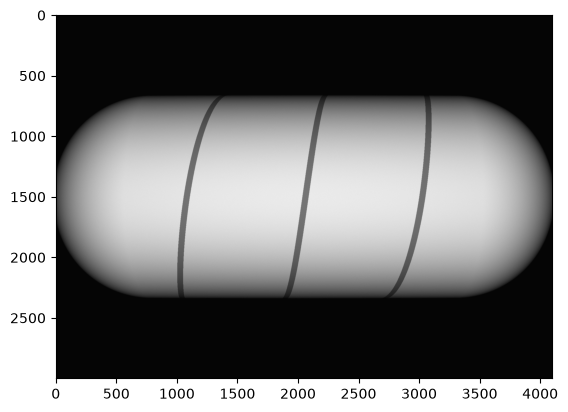

In [2]:
# import input_file

run = dataset.read_run(run_folder)
cam_img_data = dataset.read_frame(run, frame_name)
print(f"Input data shape: {cam_img_data.shape}")

#Preview the data
plt.imshow(cam_img_data, cmap='gray')


In [3]:
# Conversion (section 4). Production copy: digital_thread.conversion (kept identical by the reference test).

import numpy as np

from digital_thread.dataset import PolarisationMaps

MAX_ADU = 4095  # 12-bit: a channel at this value is saturated
AOLP_SIGN = 1  # -1 if the camera's polariser angles run counter-clockwise on screen


def convert(raw, polar_pattern):
    """Raw frame (2H x 2W) -> polarisation maps (H x W), one value per 2x2 super-pixel.

    polar_pattern: polariser angle of (top-left, top-right, bottom-left, bottom-right).
    DoLP and AoLP are NaN where a channel is saturated or S0 is zero.
    """
    raw = np.asarray(raw)
    slots = [(0, 0), (0, 1), (1, 0), (1, 1)]
    channels = {
        angle: raw[r::2, c::2].astype(np.float64)  # float: uint16 differences wrap
        for (r, c), angle in zip(slots, polar_pattern, strict=True)
    }
    i0, i45, i90, i135 = (channels[a] for a in (0, 45, 90, 135))
    saturated = np.any([ch >= MAX_ADU for ch in channels.values()], axis=0)

    s0 = 0.5 * (i0 + i45 + i90 + i135)
    s1 = i0 - i90
    s2 = AOLP_SIGN * (i45 - i135)

    valid = (s0 > 0) & ~saturated
    dolp = np.full(s0.shape, np.nan)
    dolp[valid] = np.hypot(s1[valid], s2[valid]) / s0[valid]
    aolp = np.full(s0.shape, np.nan)
    psi = 0.5 * np.degrees(np.arctan2(s2[valid], s1[valid]))
    aolp[valid] = 90.0 - np.mod(90.0 - psi, 180.0)  # wrap to (-90, 90]
    return PolarisationMaps(
        s0.astype(np.float32), dolp.astype(np.float32), aolp.astype(np.float32)
    )

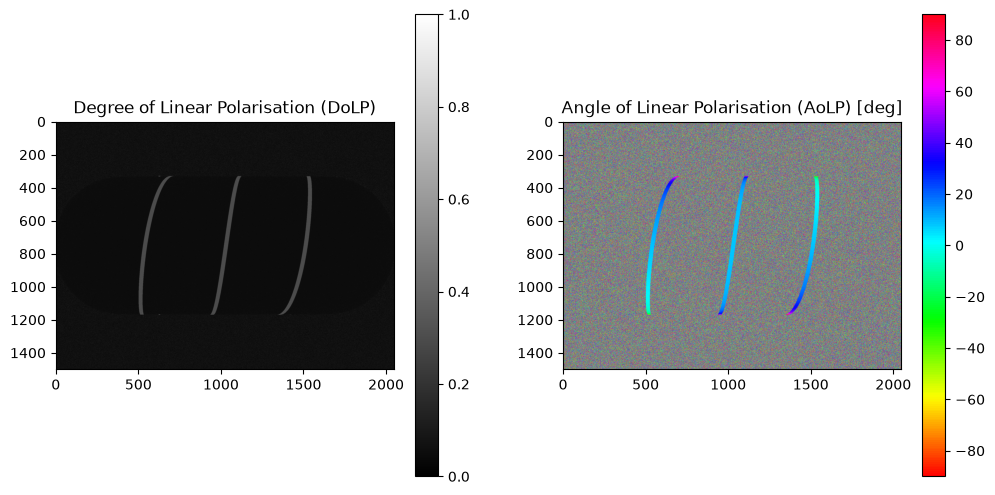

In [4]:
# Convert the selected frame with the run's polariser pattern, preview and save it.

maps = convert(cam_img_data, run.polar_pattern)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(maps.dolp, cmap='gray', vmin=0, vmax=1)
plt.title('Degree of Linear Polarisation (DoLP)')
plt.colorbar()
plt.subplot(1, 2, 2)
plt.imshow(maps.aolp, cmap='hsv', vmin=-90, vmax=90)
plt.title('Angle of Linear Polarisation (AoLP) [deg]')
plt.colorbar()
plt.show()

# Save the polarisation maps and PNG previews (production writes the maps into the run folder).
os.makedirs(save_location, exist_ok=True)
dataset.write_polarisation(save_location, frame_name, maps)
plt.imsave(save_location / "DoLP.png", maps.dolp, cmap='gray', vmin=0, vmax=1)
plt.imsave(save_location / "AoLP.png", maps.aolp, cmap='hsv', vmin=-90, vmax=90)

# 5 Mapping and flattening

Each pixel is mapped onto the mandrel model, and its AoLP is turned into a fibre angle with the inverse forward model. The result per frame is a fibre angle per valid pixel, with the 3D point and surface normal per pixel computed once per run (the camera does not move), plus a flattened image.

## Requirements
- **Geometry (once per run, production code):** the pixel ray of each super-pixel inside the crop polygon is computed from the intrinsics with distortion correction (pixel positions only; the lens does not rotate the polarisation, so the AoLP is unchanged) and cast onto the mandrel mesh. The 3D point is the nearest hit; the normal is interpolated barycentrically from the CAD vertex normals.
- **Valid pixels:** inside the crop polygon, the ray hits the mesh, incidence (angle between surface normal and line of sight) ≤ the **incidence limit (20°)**, and DoLP ≥ the **DoLP threshold (0.1)**. Beyond the incidence limit the AoLP no longer follows the fibre reliably, so the change between frames would not find the last tow there. The DoLP threshold separates tow (carbon) from the bare plastic mandrel. Both values are processing settings in `run.json`.
- **Fibre angle (notebook):** inverse forward model per valid pixel; NaN elsewhere.
- **Flattened image (notebook):** the surface unrolled onto a plane: axial position along the mandrel axis × arc length r_ref·φ about the axis, with r_ref the radius at the view centre, at 0.1 mm per pixel, holding the fibre angle. On the cylinder it is exact, and a helical tow becomes a straight band at its fibre angle; on the banana the circumferential scale is stretched where the radius differs from r_ref. It serves the overlay and finding the tow; Tow matching measures Δ position and Δ angle in 3D.
- Display and save the flattened image; save the geometry and fibre angles.
- The forward model below. Mapping inverts it, and the synthetic data generator uses it to render frames.
- Physical validation on the asymmetric demo mandrel (`Banana 1.STEP`) with known tow angles, because synthetic tests only prove that geometry and code are consistent, not the physics. It includes tow angles well away from 0° and 90°, so that a mirrored AoLP sign (section 4) shows up. It also checks the DoLP threshold on carbon against the real mandrel surface.

## Specs

**Problem.** The polarisation maps give the AoLP in image coordinates, but tow deviations must be judged as fibre angles on the mandrel surface. Without mapping, no pixel has a 3D position, a surface normal or a fibre angle, background and bare mandrel are not separated from tow, and there is no flat view in which a tow can be found and overlaid.

**Solution.** Once per run, production code computes the geometry of every super-pixel (3D point, normal) and a lookup that unrolls the surface into the flattened image. Per frame, the notebook's mapping turns the polarisation maps into a fibre angle per valid pixel with the inverse forward model and fills the flattened image. Crop polygon and processing settings come from the calibration bundle and the run.

**User stories**
1. As the researcher, I want each valid pixel to carry a fibre angle on the mandrel surface, so that tow deviations are judged in the part's own frame.
2. As the researcher, I want the fibre angle computed by the inverse forward model in the notebook, so that I take responsibility for the physics.
3. As the researcher, I want pixels beyond the incidence limit invalid, so that unreliable AoLP does not produce false tows.
4. As the researcher, I want pixels below the DoLP threshold invalid, so that bare plastic mandrel is separated from carbon tow.
5. As the researcher, I want pixels outside the crop polygon invalid, so that background and fixtures never enter the evaluation.
6. As the researcher, I want the incidence limit and the DoLP threshold recorded in the run, so that every result can be reproduced and reprocessed with other values.
7. As the researcher, I want a flattened image of the fibre angle, so that a tow appears as a straight band and can be found and overlaid.
8. As the researcher, I want the flattened image at a fixed 0.1 mm per pixel in axial position × arc length, so that distances in it are millimetres.
9. As the researcher, I want the flattened image to show only surface points the camera can see, so that hidden surface is not filled with wrong values.
10. As the researcher, I want distortion correction to move pixel positions only, so that the AoLP is not altered by the lens model.
11. As the researcher, I want normals interpolated from the CAD normals, so that the fibre angle does not jump at mesh facets.
12. As the operator, I want to draw the crop polygon once per installation, so that every run uses the same region.
13. As the developer, I want the geometry computed once per run and saved, so that each frame is mapped in seconds.
14. As the developer, I want geometry and fibre angles written and read through the dataset I/O module, so that Tow matching runs on its own from files.
15. As the developer, I want old bundles and runs without crop polygon or processing settings to load with defaults (full image, 0.1, 20°), so that existing data stays usable.
16. As the developer, I want the production mapping to equal the notebook, so that production stays faithful to the scientific code.

**Implementation decisions**
- **Run geometry module** (production, `digital_thread`): from a calibration bundle, computes per super-pixel the pixel ray (intrinsics, fixed-point inversion of the distortion model), the nearest mesh hit with Open3D, refined in float64 on the hit triangle, and the normal interpolated barycentrically from the vertex normals; NaN outside the crop polygon or where the ray misses. It also builds the **flattening lookup**: a grid at 0.1 mm per pixel in (axial position, r_ref·φ), r_ref = radius at the hit of the image centre; each grid cell casts a ray outward from the axis at its (axial position, φ), and the hit is assigned the super-pixel it projects to, only if that super-pixel's own geometry point is the same surface point (otherwise hidden, −1). The ray casting and distortion code moves from the generator into this module; Open3D moves to the production dependencies.
- **Mapping module** (notebook cell `# Mapping`, package copy): `valid_pixels(maps, geometry, cal, processing)` (inside the crop, hit, incidence ≤ limit, DoLP ≥ threshold), `fibre_angles(maps, geometry, cal, processing)` (inverse forward model on valid pixels, NaN elsewhere) and `flat_coordinates(points, axis_point, axis_dir, r_ref)` (axial position and arc length, φ zero as in the touch-down model, wrapped to within ±180° of the view centre). Flattening a per-pixel map is indexing it with the lookup.
- **Calibration bundle** gains an optional crop polygon (vertices in super-pixel coordinates of the full image); missing = full image. **Run** gains processing settings (DoLP threshold 0.1, incidence limit 20°); missing = these defaults.
- **Dataset I/O:** read/write of the run geometry (point, normal, flattening lookup, grid origin, r_ref) and of per-frame fibre angles, in a given folder, like the polarisation maps.
- **Synthetic cylinder:** a four-corner crop polygon (projection of the barrel corners at z = ±180 mm, body angle ±20°) and the processing settings are added to the committed JSON files; no regeneration.
- **Notebook:** the imports cell drops `view_incidence_threshold` (read from the run); a usage cell computes or loads the geometry (cached in `notebooks/temp_data/`), maps the selected frame and shows the flattened image, writing to the save location.

**Testing decisions**
- Tests check external behaviour at three seams: **run geometry**, **mapping**, **dataset I/O**. Expected values come from the analytic cylinder or the committed ground truth, never from the code under test.
- Geometry (cylinder): hit points at r = 125 mm and radial normals on the barrel; reprojection error < 0.05 px; pixels outside the crop polygon are NaN; the flattening lookup maps a grid cell at (z, 125·φ) to a pixel whose point lies within 0.2 mm of that surface point (a super-pixel covers about 0.25 mm).
- Mapping (cylinder, `rev002`): on new-tow pixels that are valid, over 99 % have a fibre angle and the median signed error against the true fibre angle is below 0.2°; no pixel with incidence > 20° or DoLP < 0.1 is valid; background is invalid, and fewer than 0.1 % of bare-mandrel pixels are valid (shot noise lifts a few over the threshold).
- Flattened image (cylinder): each tow's valid cells form a straight band at the helix angle + δ_k, whose centre line lies at |d_k| from the crossing point's (z, 125·φ) within 0.2 mm.
- I/O: geometry and fibre angles survive a round trip; a bundle and run without the new fields load with the defaults.
- Reference test: the package mapping equals the notebook cell.
- Prior art: `test_synthetic_dataset.py` (analytic cylinder checks), `test_conversion.py`, `test_notebook_reference.py`.

**Out of scope:** the crop polygon drawing UI (slice 2) and zeroing pixels at capture (slice 3); the banana dataset (T5) and the physical validation; tow detection and matching (slice 6); a radius-true or gnomonic flattening.

**Further notes.** With the 20° limit the cylinder view keeps about ±35 mm of arc around the line of sight over the full barrel length, which contains all three crossings. Geometry for 3 million rays takes a few seconds with Open3D and is cached per run.

## Forward model
1. **Local frame** at surface point P with normal n: e_a is the mandrel axis projected into the tangent plane; e_r = e_a × n, the surface direction of mandrel rotation (n points out of the mandrel; the axis direction is oriented so that the mandrel turns counter-clockwise about it). Fibre direction **t = cos α · e_a + sin α · e_r**.
2. **Polarisation:** with the viewing ray v = (P − camera centre)/|…|, the reflected light is polarised perpendicular to fibre and ray: **E = v × t** (normalised).
3. **AoLP:** E in camera coordinates, ψ = atan2(E_y, E_x), wrapped to (−90°, 90°].
4. **Inverse:** E is rebuilt from ψ with E ⊥ v, then **t = E × n** (normalised) and α = atan2(t·e_r, t·e_a), wrapped to (−90°, 90°]. Closed form; ill-defined at grazing view, so pixels beyond an incidence limit are dropped.
5. **Rendering only (not inverted):** DoLP = 0.3 on tow, 0.05 on the bare mandrel, 0.02 in the background. S0 = L · ρ · cos(incidence) with the light at the camera, ρ = 0.4 on tow and 0.8 on the mandrel, and L set so the brightest pixel is about 3000 of 4095 counts.

The physical validation on the banana tests assumption 2 directly.

In [5]:
# Forward model (section 5). Drafted by Claude for review by the author.
# Production copy: digital_thread.forward_model (kept identical by the reference test).
# Conventions: world vectors (..., 3) in the STEP frame (mm); x_cam = R @ X + t with camera
# x right, y down, z forward; image angles from +x towards +y; the mandrel turns
# counter-clockwise about axis_dir (right-hand rule); normals point out of the mandrel.

import numpy as np

DOLP = {"tow": 0.3, "mandrel": 0.05, "background": 0.02}
ALBEDO = {"tow": 0.4, "mandrel": 0.8}


def wrap_angle(angle_deg):
    """Wrap an orientation angle to (-90, 90] degrees."""
    return 90.0 - np.mod(90.0 - np.asarray(angle_deg, dtype=float), 180.0)


def _unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)


def fibre_frame(normal, axis_dir):
    """Local surface frame (e_a, e_r): axis direction projected into the
    tangent plane, and the surface direction of mandrel rotation."""
    normal = np.asarray(normal, dtype=float)
    axis_dir = np.asarray(axis_dir, dtype=float)
    e_a = _unit(axis_dir - np.sum(axis_dir * normal, axis=-1, keepdims=True) * normal)
    e_r = np.cross(e_a, normal)
    return e_a, e_r


def fibre_direction(fibre_deg, normal, axis_dir):
    """Unit fibre direction t = cos(a) e_a + sin(a) e_r."""
    e_a, e_r = fibre_frame(normal, axis_dir)
    a = np.radians(np.asarray(fibre_deg, dtype=float))[..., None]
    return np.cos(a) * e_a + np.sin(a) * e_r


def _view_rays(point, rot, t):
    centre = -np.asarray(rot).T @ np.asarray(t, dtype=float)
    return _unit(np.asarray(point, dtype=float) - centre)


def cos_incidence(point, normal, rot, t):
    """Cosine of the angle between surface normal and the direction to the camera."""
    return np.sum(-_view_rays(point, rot, t) * np.asarray(normal), axis=-1)


def aolp_from_fibre(fibre_deg, point, normal, axis_dir, rot, t):
    """AoLP (deg) seen by the camera: light polarised along E = v x t."""
    v = _view_rays(point, rot, t)
    e = np.cross(v, fibre_direction(fibre_deg, normal, axis_dir))
    e_cam = e @ np.asarray(rot).T
    return wrap_angle(np.degrees(np.arctan2(e_cam[..., 1], e_cam[..., 0])))


def fibre_from_aolp(aolp_deg, point, normal, axis_dir, rot, t):
    """Inverse: rebuild E from the AoLP with E perpendicular to the ray, then
    the fibre is perpendicular to E and lies in the surface: t = E x n."""
    rot = np.asarray(rot)
    v_cam = _view_rays(point, rot, t) @ rot.T
    psi = np.radians(np.asarray(aolp_deg, dtype=float))
    ex, ey = np.cos(psi), np.sin(psi)
    ez = -(ex * v_cam[..., 0] + ey * v_cam[..., 1]) / v_cam[..., 2]
    e = np.stack([ex, ey, ez], axis=-1) @ rot
    fibre = np.cross(e, normal)
    e_a, e_r = fibre_frame(normal, axis_dir)
    along_r = np.sum(fibre * e_r, axis=-1)
    along_a = np.sum(fibre * e_a, axis=-1)
    return wrap_angle(np.degrees(np.arctan2(along_r, along_a)))


def s0(albedo, cos_incidence, light):
    """Total intensity, Lambertian with the light at the camera."""
    return light * albedo * np.clip(cos_incidence, 0.0, None)


def polariser_intensity(s0, dolp, aolp_deg, polariser_deg):
    """Intensity behind a linear polariser at polariser_deg (Malus)."""
    angle = np.radians(2.0 * (np.asarray(aolp_deg) - polariser_deg))
    return 0.5 * s0 * (1.0 + dolp * np.cos(angle))

In [6]:
# Mapping (section 5). Production copy: digital_thread.mapping (kept identical by the reference test).
# Uses the forward model above (imported from its package copy so this cell also runs on its own).

import numpy as np

from digital_thread.forward_model import cos_incidence, fibre_from_aolp


def valid_pixels(maps, geo, cal, processing):
    """Valid pixel: inside the crop polygon and on the mandrel (geometry not NaN),
    incidence <= limit, DoLP >= threshold and a finite AoLP."""
    hit = ~np.isnan(geo.point[..., 0])
    valid = np.zeros(hit.shape, dtype=bool)
    point = geo.point[hit].astype(np.float64)
    normal = geo.normal[hit].astype(np.float64)
    steep = cos_incidence(point, normal, cal.R, cal.t) < np.cos(
        np.radians(processing.incidence_limit_deg)
    )
    dolp, aolp = maps.dolp[hit], maps.aolp[hit]
    with np.errstate(invalid="ignore"):  # NaN DoLP compares as False
        polarised = dolp >= processing.dolp_threshold
    valid[hit] = ~steep & polarised & np.isfinite(aolp)
    return valid


def fibre_angles(maps, geo, cal, processing):
    """Fibre angle (deg) per valid pixel by the inverse forward model, NaN elsewhere."""
    valid = valid_pixels(maps, geo, cal, processing)
    fibre = np.full(valid.shape, np.nan, dtype=np.float32)
    fibre[valid] = fibre_from_aolp(
        maps.aolp[valid].astype(np.float64),
        geo.point[valid].astype(np.float64),
        geo.normal[valid].astype(np.float64),
        cal.axis_dir,
        cal.R,
        cal.t,
    )
    return fibre


def axis_frame(axis_dir):
    """Unit axis a and the directions e1, e2 of body angle 0 and 90 deg about it.
    Body angle zero is the STEP X direction projected normal to the axis (Y if
    the axis is along X), counter-clockwise about a, as in the touch-down model."""
    a = np.asarray(axis_dir, dtype=float)
    a = a / np.linalg.norm(a)
    zero = np.array([1.0, 0.0, 0.0]) if abs(a[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    e1 = zero - (zero @ a) * a
    e1 /= np.linalg.norm(e1)
    return a, e1, np.cross(a, e1)


def flat_coordinates(points, axis_point, axis_dir, r_ref, phi_centre_deg):
    """Flattened coordinates (mm) of surface points: axial position along the axis
    and arc length r_ref * phi, with the body angle phi within +-180 deg of the
    view centre."""
    a, e1, e2 = axis_frame(axis_dir)
    rel = np.asarray(points, dtype=float) - axis_point
    phi = np.degrees(np.arctan2(rel @ e2, rel @ e1))
    phi = phi_centre_deg + (phi - phi_centre_deg + 180.0) % 360.0 - 180.0
    return rel @ a, r_ref * np.radians(phi)


def flatten(per_pixel, geo):
    """Flattened image of a per-pixel map: each grid cell takes the value of the
    super-pixel that sees its surface point (NaN where hidden or outside)."""
    image = np.full(geo.flat_pixel.shape, np.nan, dtype=np.float32)
    seen = geo.flat_pixel >= 0
    image[seen] = np.asarray(per_pixel).reshape(-1)[geo.flat_pixel[seen]]
    return image

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


valid pixels: 19230 (DoLP >= 0.1, incidence <= 20.0 deg)


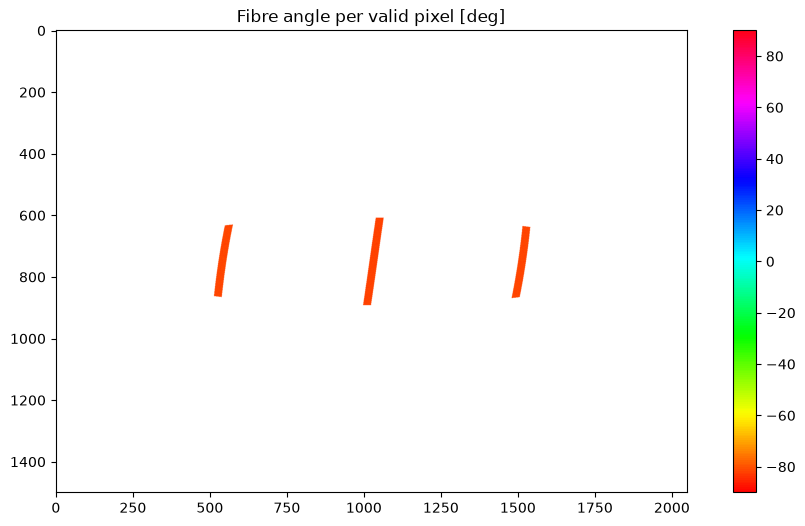

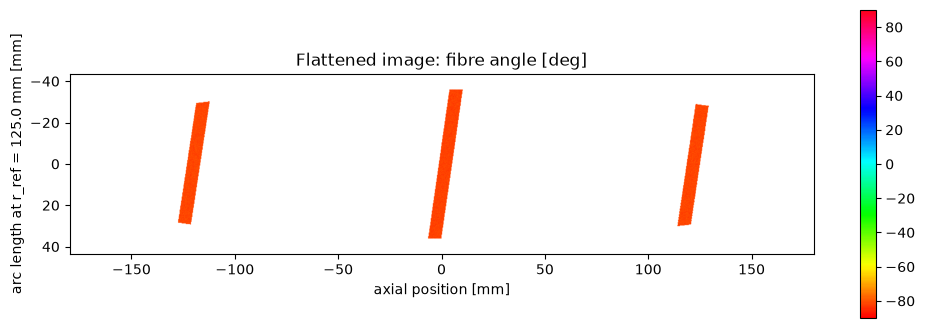

In [7]:
# Map the selected frame: run geometry (production code, once per run, cached), then fibre angles.

from digital_thread import geometry

cal = dataset.read_calibration(run.calibration_folder)
geometry_folder = save_location.parent / "synthetic_cylinder_geometry"
if (geometry_folder / dataset.GEOMETRY_FILE).exists():
    geo = dataset.read_geometry(geometry_folder)
else:
    geo = geometry.compute(cal)
    os.makedirs(geometry_folder, exist_ok=True)
    dataset.write_geometry(geometry_folder, geo)

fibre = fibre_angles(maps, geo, cal, run.processing)
dataset.write_fibre(save_location, frame_name, fibre)
print(f"valid pixels: {np.isfinite(fibre).sum()} (DoLP >= {run.processing.dolp_threshold}, "
      f"incidence <= {run.processing.incidence_limit_deg} deg)")

plt.figure(figsize=(12, 6))
plt.imshow(fibre, cmap='hsv', vmin=-90, vmax=90)
plt.title('Fibre angle per valid pixel [deg]')
plt.colorbar()
plt.show()

# Flattened image (axial position x arc length, 0.1 mm per cell) of the fibre angle.
flat = flatten(fibre, geo)
extent = [geo.flat_origin[0], geo.flat_origin[0] + geo.flat_spacing * flat.shape[1],
          geo.flat_origin[1] + geo.flat_spacing * flat.shape[0], geo.flat_origin[1]]
plt.figure(figsize=(12, 4))
plt.imshow(flat, cmap='hsv', vmin=-90, vmax=90, extent=extent)
plt.xlabel('axial position [mm]')
plt.ylabel(f'arc length at r_ref = {geo.r_ref:.1f} mm [mm]')
plt.title('Flattened image: fibre angle [deg]')
plt.colorbar()
plt.show()
plt.imsave(save_location / "flattened_fibre.png", flat, cmap='hsv', vmin=-90, vmax=90)

# 6 Tow matching

For each revolution *k*, the tow laid in that revolution is taken from the tow placement file and compared with the measured tow (the change between frames *k−1* and *k*) at its crossing point. The result is a tow table and an overlay in the flattened image.

## Requirements
- Import a tow placement file (Format: .csv with columns Point number, X, Y, Z in mm; see `demoData/planned_Path.csv`). The file can be coarse (banana: segments up to 41 mm, chords up to about 2 mm below the surface), so the planned path is resampled at 1 mm on the mesh first. Revolutions are assigned with the touch-down model.
- **Crossing point:** where the revolution's planned path crosses the plane through the camera centre and the mandrel axis, on the camera side. A revolution whose path never comes within 2 mm of the plane has no crossing point. It is **visible** if it lies inside the crop polygon within the incidence limit (checked as: a valid run-geometry pixel sees it within 1 mm, which holds while a super-pixel covers less than 1 mm of surface); otherwise the revolution gets a "not visible" row. Tow fragments elsewhere in the view (e.g. a tow cutting a corner of the view) are ignored. The **planned angle** is the fibre angle of the planned path's tangent at the crossing point.
- **Measured tow of revolution k:** valid pixels of frame *k* that were not valid in frame *k−1* (bare mandrel before) or whose fibre angle changed by more than **5°** (new tow over an older one at another angle); for *k = 0* the reference frame is frame *k−1*. Only connected regions of at least about one tow width squared (40 mm²) are kept. *Limitation:* a new tow laid over an older one at nearly the same angle is not found.
- **Δ position and Δ angle:** in the flattened image, the measured tow cells within ±15 mm along and ±10 mm across the tow from the crossing point are fitted with a centre line (at least 1 mm² of tow cells, else no measurement). The circumferential component is first corrected from r_ref to the local radius at the crossing point (exact on the cylinder, first order on the banana). Δ position = signed distance of that line from the planned crossing point, perpendicular to the line and oriented along n × t (n outward normal, t planned direction of travel), so a tow laid towards n × t gives a positive Δ position; **Δ angle = direction of the fitted centre line − planned angle** (geometric; the polarisation-based fibre angle is used for finding the tow, not for Δ angle).
- **Outputs:** one tow table per run (CSV: revolution, visible, crossing point x, y, z, planned angle, Δ position, Δ angle, number of tow cells used), and one overlay image per revolution: the flattened image with the measured tow and the planned tow edges (± tow width / 2).

## Specs

**Problem.** Mapping gives a fibre angle per valid pixel and frame, but nothing yet says where the tow of a revolution actually landed compared with the plan. Without that comparison the system cannot report deviations to the digital thread.

**Solution.** Per run, the planned path is resampled on the mesh and split into revolutions with the touch-down model. For each revolution, the crossing point and planned angle are taken from the plan; the measured tow is the change between frames *k−1* and *k*; a centre line fitted to the measured tow near the crossing point gives Δ position and Δ angle. The result is a tow table (one row per revolution, "not visible" where the crossing point is outside the valid view) and an overlay image per revolution.

**User stories**
1. As the researcher, I want one row per revolution with planned position and angle and the measured Δ position and Δ angle, so that I can judge each tow's placement.
2. As the researcher, I want the tow matching rules written in the notebook, so that I take responsibility for how a tow is found and measured.
3. As the researcher, I want the measured tow defined as the change between consecutive frames, so that earlier tows do not count as the new one.
4. As the researcher, I want a new tow over an older one found when the fibre angle changes by more than 5°, so that crossing tows are separated.
5. As the researcher, I want small changed regions discarded, so that noise and single pixels do not become tows.
6. As the researcher, I want the comparison made at the crossing point, so that every revolution is evaluated at one well-defined place.
7. As the researcher, I want a revolution whose crossing point is outside the valid view reported as "not visible", so that missing measurements are explicit.
8. As the researcher, I want tow fragments away from the crossing point ignored, so that a tow cutting a corner of the view is not mistaken for a crossing.
9. As the researcher, I want Δ angle from the direction of the fitted centre line, so that it measures where the tow lies, independent of the polarisation model.
10. As the researcher, I want the flattened image's circumferential stretch corrected at the crossing point, so that Δ position and Δ angle are in true millimetres and degrees on the surface.
11. As the researcher, I want Δ position signed along n × t, so that its sign matches the ground truth and the digital thread.
12. As the researcher, I want an overlay of the measured tow and the planned tow edges per revolution, so that I can check each result by eye.
13. As the operator, I want the tow table as CSV in the run folder, so that slice 7 and other tools can read it.
14. As the developer, I want the coarse tow placement file resampled on the mesh, so that planned positions lie on the surface.
15. As the developer, I want the production tow matching to equal the notebook, so that production stays faithful to the scientific code.

**Implementation decisions**
- **Planned path** (production geometry module): resample the tow placement file at 1 mm along the polyline and project onto the mesh (points and normals); the code moves from the generator. Points further than one tow width from the mesh are dropped first. Revolutions by the touch-down model.
- **Tow matching module** (notebook cell `# Tow matching`, package copy):
  - `measured_tow(fibre_before, fibre_after, geo)`: valid in *after* and (invalid in *before* or |Δ fibre angle| > 5°), then connected regions in the flattened image smaller than 40 mm² removed (SciPy, which moves into the production dependencies).
  - `crossing(path, normals, revolution, cal)`: index of the crossing point within the revolution (plane through camera centre and axis, camera side, surface facing the camera), planned angle from the path tangent in the local fibre frame, and visibility (inside the crop polygon, incidence ≤ limit).
  - `match_revolution(...)`: measured tow cells within ±15 mm along the tow from the crossing point in the flattened image, circumferential coordinate scaled by r(crossing)/r_ref, centre line by principal axis; Δ position = signed distance of the crossing point from the line along n × t; Δ angle = line direction − planned angle, wrapped to (−90°, 90°].
  - `tow_table(run, cal, geo, fibre_maps)`: one row per revolution frame in the frame log, numbered from the frame name (a missed revolution leaves a gap; its tow then joins the change measured for the next frame, away from that frame's crossing point): revolution, visible, crossing point x, y, z, planned angle, Δ position, Δ angle, number of tow cells; NaN deltas for not-visible rows or when no tow cell is found near a visible crossing.
- **Dataset I/O:** write/read the tow table (`tow_table.csv`, in a given folder).
- **Overlay:** per revolution an RGB image of the flattened image: measured tow cells coloured, planned tow edges (± tow width / 2 around the planned path) drawn; written as `revNNN_overlay.png`.
- **Notebook:** a usage cell maps all frames of the selected run, builds the tow table, shows it and the overlay of the selected revolution, and writes both to the save location.

**Testing decisions**
- Seams: the **tow matching module** (end to end from fibre maps to the tow table) and the **dataset I/O module**. Expected values come from the committed ground truth (`truth.json`: d_k, δ_k, crossing point, visible).
- Both mandrels, visible revolutions: |Δ position − d_k| < 1 mm and |Δ angle − δ_k| < 1°; crossing point within 1 mm of the truth's; visible flag equals the truth's.
- Banana: revolution 1 is "not visible" with NaN deltas.
- Measured tow: on the cylinder `rev002`, the measured tow of revolution 2 covers over 95 % of the valid new-tow pixels of the truth and contains no pixel of an earlier tow outside the new one.
- I/O: the tow table survives a round trip.
- Reference test: the package tow matching equals the notebook cell on fixed inputs.
- Prior art: `test_mapping.py`, `test_flattening.py`, `test_banana_mapping.py`, `test_notebook_reference.py`.

**Out of scope:** tows laid over older tows at nearly the same angle (stated limitation); more than one crossing per revolution; Δ angle from the polarisation fibre angle; slice 7 export formats and the 3DEXPERIENCE adapter; real-time processing during capture.

**Further notes.** Thresholds (5°, 40 mm², ±15 mm) are fixed for now and can become processing settings if the physical validation asks for it. On the banana, the r_ref correction is first order; the ±15 mm window keeps the error from the varying radius small.

In [8]:
# Touch-down model (shared conventions, used by section 6). Drafted by Claude for review.
# Production copy: digital_thread.touch_down (kept identical by the reference test).

import numpy as np


def body_angle(points, axis_point, axis_dir):
    """Unwrapped angle (deg) of each path point about the axis, counter-clockwise
    about axis_dir (right-hand rule), in path order. Zero is the STEP X
    direction projected normal to the axis (Y if the axis is along X)."""
    a = np.asarray(axis_dir, dtype=float)
    a = a / np.linalg.norm(a)
    zero = np.array([1.0, 0.0, 0.0]) if abs(a[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    e1 = zero - (zero @ a) * a
    e1 /= np.linalg.norm(e1)
    e2 = np.cross(a, e1)
    rel = np.asarray(points, dtype=float) - axis_point
    return np.degrees(np.unwrap(np.arctan2(rel @ e2, rel @ e1)))


def mandrel_angle(points, axis_point, axis_dir, touch_down_deg, pin_phase_deg):
    """Mandrel angle (deg, counted from the last pin pulse before winding) at
    which each point is laid. A point at body angle phi touches down when
    mandrel angle + phi = touch-down angle, so later tow lies at smaller phi.
    The first point is laid within the first revolution."""
    phi = body_angle(points, axis_point, axis_dir)
    first = np.mod(touch_down_deg - phi[0] - pin_phase_deg, 360.0)
    return first + (phi[0] - phi)


def revolution_index(points, axis_point, axis_dir, touch_down_deg, pin_phase_deg):
    """Revolution k in which each point is laid (k = 0 for the first point)."""
    theta = mandrel_angle(points, axis_point, axis_dir, touch_down_deg, pin_phase_deg)
    return np.floor(theta / 360.0).astype(int)

In [9]:
# Tow matching (section 6). Production copy: digital_thread.tow_matching (kept identical by the reference test).
# Uses the forward model and mapping above (imported from their package copies so this cell also runs on its own).

from dataclasses import dataclass

import numpy as np
from scipy import ndimage

from digital_thread.forward_model import cos_incidence, fibre_frame, wrap_angle
from digital_thread.mapping import flat_coordinates, flatten

SAME_POINT_MM = 1.0  # the pixel that sees the crossing point lies this close to it
MAX_OFF_PLANE_MM = 2.0  # a revolution that never reaches the plane has no crossing
MIN_CHANGE_DEG = 5.0  # new tow over an older one at another angle
MIN_AREA_MM2 = 40.0  # about one tow width squared; smaller changes are noise
WINDOW_ALONG_MM = 15.0  # measured tow used for the centre line, along the tow
WINDOW_ACROSS_MM = 10.0  # and across it, around the crossing point
MIN_CELLS = 100  # 1 mm2 of measured tow at least, else no measurement


@dataclass
class Crossing:
    """Crossing point of a revolution's planned path (plane through camera centre
    and mandrel axis, camera side), its planned fibre angle and visibility."""

    index: int  # index into the planned path, -1 if the revolution never crosses
    point: np.ndarray  # mm
    normal: np.ndarray
    tangent: np.ndarray  # planned direction of travel
    planned_deg: float
    visible: bool


def crossing(planned, k, cal, geo, processing):
    """Crossing point of revolution k. Visible if a pixel inside the crop polygon
    sees it and its incidence is within the limit."""
    axis = cal.axis_dir / np.linalg.norm(cal.axis_dir)
    centre = -cal.R.T @ cal.t
    towards_camera = centre - cal.axis_point
    towards_camera -= (towards_camera @ axis) * axis
    plane_normal = np.cross(axis, towards_camera)
    plane_normal /= np.linalg.norm(plane_normal)

    rel = planned.point - cal.axis_point
    facing = np.einsum("ij,ij->i", planned.point - centre, planned.normal) < 0
    candidate = (planned.revolution == k) & facing & (rel @ towards_camera > 0)
    off_plane = np.where(candidate, np.abs(rel @ plane_normal), np.inf)
    i = int(np.argmin(off_plane))
    if not off_plane[i] <= MAX_OFF_PLANE_MM:
        nan = np.full(3, np.nan)
        return Crossing(-1, nan, nan, nan, np.nan, False)

    p, n = planned.point[i], planned.normal[i]
    t = planned.point[min(i + 1, len(rel) - 1)] - planned.point[max(i - 1, 0)]
    t /= np.linalg.norm(t)
    e_a, e_r = fibre_frame(n, cal.axis_dir)
    planned_deg = float(wrap_angle(np.degrees(np.arctan2(t @ e_r, t @ e_a))))

    with np.errstate(invalid="ignore"):
        seen = np.nanmin(np.linalg.norm(geo.point - p, axis=-1)) < SAME_POINT_MM
    steep = cos_incidence(p, n, cal.R, cal.t) < np.cos(
        np.radians(processing.incidence_limit_deg)
    )
    return Crossing(i, p, n, t, planned_deg, bool(seen and not steep))


def measured_tow(fibre_before, fibre_after, geo):
    """Measured tow in the flattened image: cells valid after that were invalid
    before or whose fibre angle changed by more than MIN_CHANGE_DEG, in connected
    regions of at least MIN_AREA_MM2."""
    valid_before, valid_after = np.isfinite(fibre_before), np.isfinite(fibre_after)
    with np.errstate(invalid="ignore"):
        turned = np.abs(wrap_angle(fibre_after - fibre_before)) > MIN_CHANGE_DEG
    changed = valid_after & (~valid_before | turned)
    flat = flatten(changed.astype(np.float32), geo) == 1
    labels, _ = ndimage.label(flat)
    area = np.bincount(labels.ravel()) * geo.flat_spacing**2
    keep = area >= MIN_AREA_MM2
    keep[0] = False  # background
    return keep[labels]


def match_revolution(tow_cells, cross, cal, geo):
    """Delta position (mm, along n x t) and Delta angle (deg) of the measured tow
    at the crossing point, from a centre line fitted in the flattened image.

    Coordinates are relative to the crossing point; the circumferential one is
    rescaled from r_ref to the radius at the crossing point. Returns
    (delta_position_mm, delta_angle_deg, cells used).
    """
    axis = cal.axis_dir / np.linalg.norm(cal.axis_dir)
    axial_c, arc_c = flat_coordinates(
        cross.point[None], cal.axis_point, axis, geo.r_ref, geo.phi_centre_deg
    )
    rel = cross.point - cal.axis_point
    scale = np.linalg.norm(rel - (rel @ axis) * axis) / geo.r_ref
    rows, cols = np.nonzero(tow_cells)
    xy = np.column_stack(
        [
            geo.flat_origin[0] + geo.flat_spacing * cols - axial_c[0],
            (geo.flat_origin[1] + geo.flat_spacing * rows - arc_c[0]) * scale,
        ]
    )
    # Planned direction of travel and side n x t in (axial, arc) coordinates.
    e_a, e_r = fibre_frame(cross.normal, cal.axis_dir)
    d = np.array([cross.tangent @ e_a, cross.tangent @ e_r])
    d /= np.linalg.norm(d)
    near = (np.abs(xy @ d) <= WINDOW_ALONG_MM) & (
        np.abs(xy @ np.array([d[1], -d[0]])) <= WINDOW_ACROSS_MM
    )
    if near.sum() < MIN_CELLS:
        return np.nan, np.nan, int(near.sum())
    pts = xy[near]
    centre = pts.mean(axis=0)
    u = np.linalg.svd(pts - centre, full_matrices=False)[2][0]
    u = u if u @ d > 0 else -u
    delta_angle = wrap_angle(np.degrees(np.arctan2(u[1], u[0])) - cross.planned_deg)
    delta_position = centre @ np.array([u[1], -u[0]])  # side of the measured line
    return float(delta_position), float(delta_angle), int(near.sum())


def tow_table(run, cal, geo, planned, fibre_maps):
    """One row per revolution: crossing point, planned angle and the measured
    Delta position / Delta angle (NaN if not visible or no tow found).
    fibre_maps: fibre angle per pixel for each frame name of the run.

    The frame log starts with the reference frame; the revolution index comes
    from each frame's name (set from the timestamps in Data capturing), so a
    missed revolution leaves a gap instead of shifting the numbering. The
    measured tow is the change from the previous frame in the log."""
    rows = []
    names = [f.name for f in run.frames]
    for i in range(1, len(names)):
        name, before = names[i], names[i - 1]
        k = int(name.removeprefix("rev"))
        cross = crossing(planned, k, cal, geo, run.processing)
        delta_position = delta_angle = np.nan
        cells = 0
        if cross.visible:
            tow = measured_tow(fibre_maps[before], fibre_maps[name], geo)
            delta_position, delta_angle, cells = match_revolution(tow, cross, cal, geo)
        rows.append(
            {
                "revolution": k,
                "visible": cross.visible,
                "x_mm": float(cross.point[0]),
                "y_mm": float(cross.point[1]),
                "z_mm": float(cross.point[2]),
                "planned_angle_deg": cross.planned_deg,
                "delta_position_mm": delta_position,
                "delta_angle_deg": delta_angle,
                "tow_cells": cells,
            }
        )
    return rows

rev visible planned [deg] dpos [mm] dang [deg]  cells
  0    True        -81.31    -0.008     -0.016  19068
  1    True        -81.31    -1.829     -0.581  19085
  2    True        -81.31    -1.739     -0.138  19033


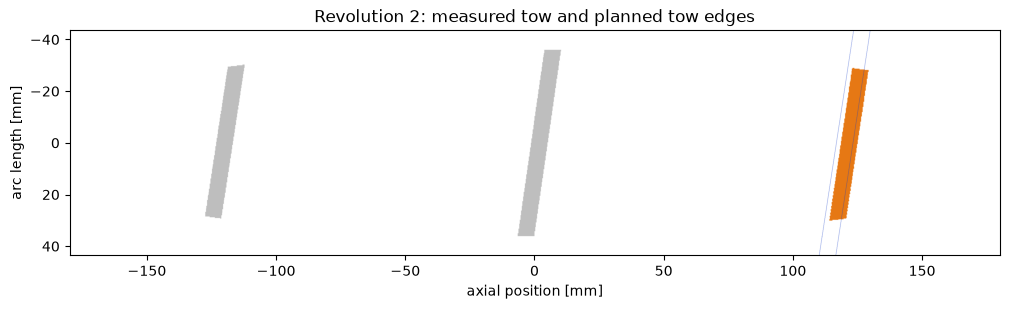

In [10]:
# Tow matching of the run: fibre angles of all frames, planned path (production code), tow table and overlay.

from digital_thread import conversion, geometry as run_geometry, overlay

fibre_maps = {
    f.name: fibre_angles(conversion.convert(dataset.read_frame(run, f.name), run.polar_pattern), geo, cal, run.processing)
    for f in run.frames
}
planned = run_geometry.planned_path(cal, dataset.read_path(run.folder / run.tow_file), run.tow_width_mm)
rows = tow_table(run, cal, geo, planned, fibre_maps)
dataset.write_tow_table(save_location, rows)

print(f"{'rev':>3} {'visible':>7} {'planned [deg]':>13} {'dpos [mm]':>9} {'dang [deg]':>10} {'cells':>6}")
for r in rows:
    print(f"{r['revolution']:>3} {str(r['visible']):>7} {r['planned_angle_deg']:>13.2f} "
          f"{r['delta_position_mm']:>9.3f} {r['delta_angle_deg']:>10.3f} {r['tow_cells']:>6}")

# Overlay per revolution: measured tow (orange) and planned tow edges (blue); the selected one is shown.
selected = int(frame_name[3:]) if frame_name.startswith("rev") else 0
for r in rows:
    k = r["revolution"]
    before = "reference" if k == 0 else f"rev{k - 1:03d}"
    tow = measured_tow(fibre_maps[before], fibre_maps[f"rev{k:03d}"], geo)
    image = overlay.overlay_image(fibre_maps[f"rev{k:03d}"], tow, planned, k, cal, geo, run.tow_width_mm)
    plt.imsave(save_location / f"rev{k:03d}_overlay.png", image)
    if k == selected:
        plt.figure(figsize=(12, 4))
        plt.imshow(image, extent=extent)
        plt.xlabel('axial position [mm]')
        plt.ylabel('arc length [mm]')
        plt.title(f'Revolution {k}: measured tow and planned tow edges')
        plt.show()

# 7 Data export

A finished run is processed in one go (Conversion → Mapping → Tow matching → Export) and handed to the digital thread as an **export package**. The 3DEXPERIENCE adapter is future work; it will convert from the export package.

## Requirements
- **Process a run:** one entry point takes a finished run folder through slices 4–7 (production command; the slice 1–3 GUI calls the same function later). Re-running overwrites the previous outputs and gives identical results.
- **Export package:** folder `export/` in the run folder, in neutral formats (CSV, JSON, NPZ, PNG):
  - `tow_table.csv`: the tow table of slice 6 plus the frame timestamp of each revolution;
  - `export.json`: run ID, part (STEP file name), tow file, processing settings, camera pose, export time, and the conventions (STEP frame in mm, angle definitions, sign of Δ position);
  - per revolution `revNNN_flat.npz`: flattened fibre angle, measured-tow mask, grid origin and spacing (millimetre grid, enough to redo the tow matching);
  - per revolution the overlay image.
  Per-pixel arrays (polarisation maps, fibre angles per pixel, run geometry) stay in the run folder and are not exported. No software or input-file provenance is recorded.
- **Tow viewer:** a window to click through all tows of a run (previous/next and a revolution list), showing per revolution the overlay in the flattened image, the camera image of that frame with the crossing point marked, and its row of the tow table (Δ position, Δ angle or "not visible"). A simple version now, reading only the export package and the run folder; the touch GUI of slice 1 embeds or replaces it.

## Specs

**Problem.** The slices run cell by cell in the notebook, and their outputs are spread over the run folder in internal formats. There is no single step that turns a finished run into results, no self-describing package the digital thread can take over, and no way to look through the tows of a run.

**Solution.** One command processes a finished run through slices 4–7 and writes an export package; a simple tow viewer reads that package and steps through the revolutions.

**User stories**
1. As the operator, I want to process a finished run with one command, so that I do not need the notebook in production.
2. As the operator, I want re-processing to overwrite the previous results identically, so that a run can be processed again after a fix.
3. As the operator, I want the run geometry reused when it already exists, so that re-processing is fast.
4. As the digital-thread engineer, I want an export package in neutral formats, so that the 3DEXPERIENCE adapter and other tools can read it without this software.
5. As the digital-thread engineer, I want the tow table with the frame timestamp of each revolution, so that results can be linked to the winding machine's log.
6. As the digital-thread engineer, I want run ID, part, tow file, processing settings, camera pose and export time in the package, so that results are identified.
7. As the digital-thread engineer, I want the conventions (STEP frame, mm, angle definitions, sign of Δ position) stated in the package, so that values are interpreted correctly.
8. As the researcher, I want the flattened fibre angle and the measured-tow mask of each revolution in millimetres, so that the tow matching can be redone or refined from the package.
9. As the researcher, I want the overlay of each revolution in the package, so that results can be checked without the viewer.
10. As the operator, I want to click through all tows of a run, so that I can check each revolution by eye.
11. As the operator, I want to see the overlay, the camera image with the crossing point marked and the table row side by side, so that numbers and images can be compared.
12. As the operator, I want not-visible revolutions shown as such, so that missing measurements are obvious.
13. As the developer, I want the viewer to read only the export package and the run folder, so that it also proves the package is complete.
14. As the developer, I want processing to write to a chosen output folder, so that tests and the notebook never change the committed synthetic runs.

**Implementation decisions**
- **Process module** (production): `process_run(run_folder, out_folder=None)` → path of the export package. Steps: read run and calibration bundle; run geometry (read from the output folder if present, else computed and written); per frame Conversion and Mapping, writing polarisation maps and fibre angles; planned path; tow table; export package. All derived files go to the output folder (default: the run folder); the export package is replaced as a whole on re-processing. Revolutions are numbered from the frame names, so a missed revolution leaves a gap in the table. Command-line entry point with the run folder (and an optional output folder) as arguments.
- **Export package** (folder `export/` in the output folder), written and read through the dataset I/O module (`write_export`/`read_export`):
  - `tow_table.csv`: tow table columns plus `timestamp_s` of the revolution's frame;
  - `export.json`: run ID, part (name of the folder holding the calibration bundle; the STEP file name is not stored in the bundle), tow file, processing settings, camera pose (R, t, camera centre), export time (ISO 8601), conventions (text);
  - `revNNN_flat.npz`: `fibre_deg` (flattened, float32), `tow` (bool), grid origin, spacing, r_ref; for not-visible revolutions too;
  - `revNNN_overlay.png`.
- **Tow viewer** (production, matplotlib): opens on a processed run (export package + run folder); three panels (overlay; camera image of the frame as S0 with the crossing point projected and marked; the table row as text) plus Previous/Next buttons and a revolution list. Command-line entry point with the run folder. The camera image is computed from the raw frame (super-pixel sum); the projection uses the calibration bundle.
- **Notebook:** a cell processes the selected run into the save location and opens the viewer.

**Testing decisions**
- Seams: the **process module** (end to end), the **dataset I/O module** (export package) and the **tow viewer** (light). Expected values come from the committed ground truth; outputs go to a temporary folder (the run geometry from the session fixtures is written there first, so processing reuses it).
- Both mandrels: the export package is complete (table, `export.json`, one flat array and overlay per revolution); the tow table matches the truth within 1 mm and 1° for visible revolutions and is "not visible" otherwise; timestamps equal the frame log.
- `export.json` holds the run ID, the processing settings, the camera centre (equal to −Rᵀt) and the conventions block.
- Processing twice gives identical tow tables and flat arrays.
- Viewer: opens on a processed synthetic run without a display (Agg backend), steps through all revolutions, and its text panel shows each revolution's Δ values or "not visible".
- Prior art: `test_tow_matching.py`, `test_dataset_io.py`.

**Out of scope:** the 3DEXPERIENCE adapter; zip or container formats; provenance (software version, input hashes); the touch GUI (slice 1); processing during capture.

**Further notes.** Processing a synthetic run takes about a minute, mostly the run geometry; reuse of the cached geometry makes re-processing fast. The export package is under 1 MB per run, since the flat arrays compress well.

export package: C:\Users\U8021993\OneDrive - UniSQ\Documents\01_Projects\01_MonitoringSystem_FilamentWindind\02_Software\04_DigitalThreadIntegration\notebooks\temp_data\synthetic_cylinder_processed\export


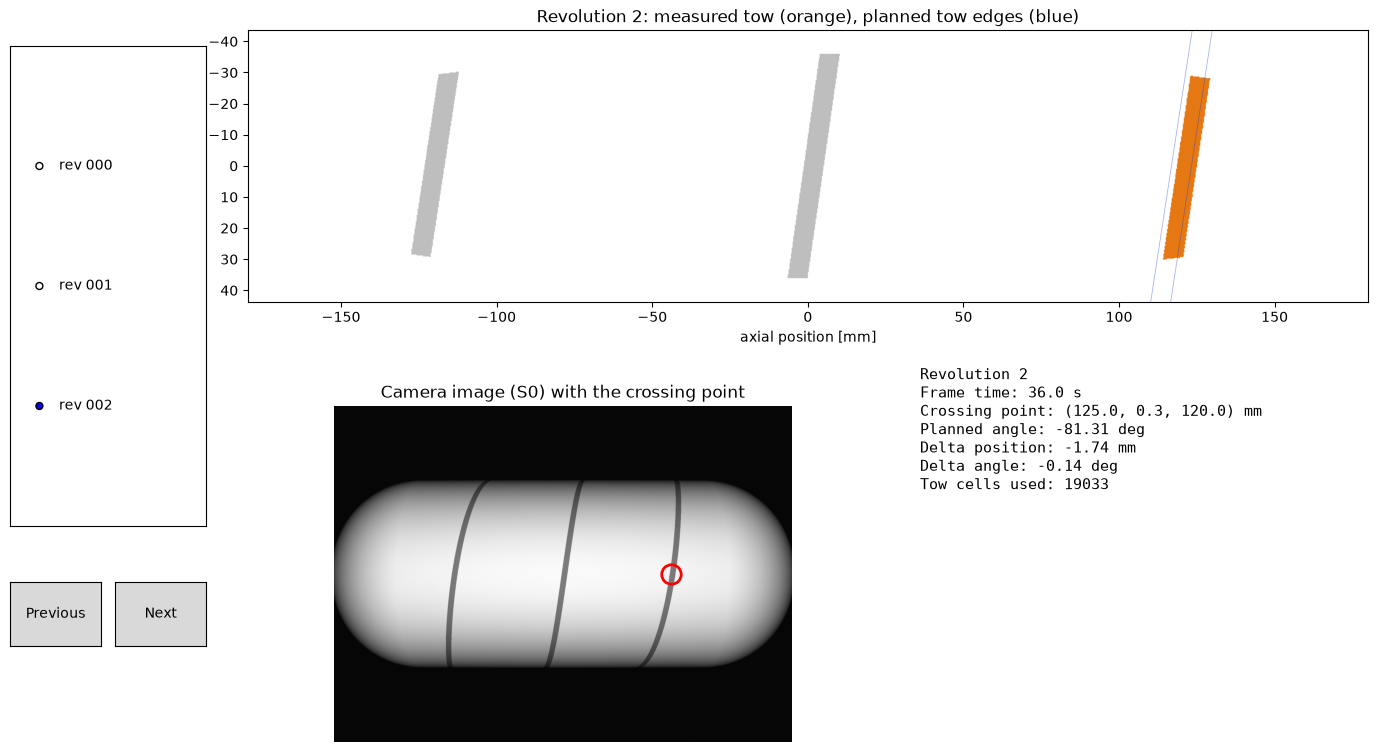

In [11]:
# Process the selected run (slices 4-7) into the save location and show the tow viewer.
# In production: `uv run python -m digital_thread.process <run_folder>` and
# `uv run python -m digital_thread.viewer <run_folder>` (interactive buttons need a GUI window).

from digital_thread import process, viewer

processed_folder = save_location.parent / f"{run.run_id}_processed"
os.makedirs(processed_folder, exist_ok=True)
dataset.write_geometry(processed_folder, geo)  # reuse the run geometry computed above
export_folder = process.process_run(run_folder, processed_folder)
print(f"export package: {export_folder}")

tows = viewer.TowViewer(run_folder, processed_folder)
tows.show(int(frame_name[3:]) if frame_name.startswith("rev") else 0)
plt.show()

# 8 Capture and processing stations

Production only. The operator works at the winder on a **capture station** (Raspberry Pi 5 with a 15.6" touchscreen, the camera on USB3). A **processing station** (a Windows workstation, for now the author's laptop) stores all data, solves calibrations and processes runs. The two are linked by Ethernet through a switch (Teltonika TSW202) and exchange **jobs** as files in one shared folder.

### Requirements
- The operator uses only the capture station: Preview, calibration capture, Record and Results, all in the app of section 1.
- The processing station is started once from a desktop shortcut and then needs no input. It shows a log and whether the capture station is connected.
- All data lives in one shared folder on the processing station, outside OneDrive, mounted by the capture station.
- Calibrations are solved on the processing station; runs are processed there automatically after Stop.
- Recording never waits for the network: each frame is written on the capture station first and copied to the shared folder straight away.
- A run folder carries its own copy of the calibration bundle.
- When the processing station is not running, the capture station shows "Processing station offline"; capture still works and jobs wait.
- One app for both stations; a role setting chooses what it does. Without a role, the app works on one machine as today.

### Specs

**Problem.** The camera has to sit at the winder, but calibration and processing need a workstation (gmsh, heavy per-pixel geometry), and the workstation is too far away for a USB3 cable. The operator should not have to walk between machines, and the workstation should run unattended.

**Solution.** The app runs on a Raspberry Pi at the winder as the capture station: the operator previews, captures calibration images, records and opens results there. A small program on the workstation, the processing station, watches a shared folder: it solves calibration jobs, processes finished runs and writes the results back, where the Pi shows them.

**User stories**
1. As the operator, I want to do everything at the winder's touchscreen, so that I never walk to the workstation during winding.
2. As the operator, I want the same tabs and layout as before, so that the manual and my habits still apply.
3. As the operator, I want to capture board and marker images on the capture station and press Solve, so that the calibration is solved without me moving to the workstation.
4. As the operator, I want "Solving on the processing station…" shown and then the same result text as before (RMS errors, marker errors, warnings, body angle), so that I can judge the calibration at the winder.
5. As the operator, I want to enter the touch-down angle and draw the crop polygon after the solve, as before, so that the calibration workflow does not change.
6. As the operator, I want a calibration error on the processing station shown on the capture station, so that I know to repeat a step.
7. As the operator, I want Record to work even if the network drops, so that a winding is never lost.
8. As the operator, I want frames that could not be copied to be copied once the network is back, so that the run in the shared folder is complete.
9. As the operator, I want each run processed automatically after Stop, so that results are ready without a further step.
10. As the operator, I want the Results tab to list the runs with their state (copying, waiting, processing with progress, done, failed), so that I know when results are ready.
11. As the operator, I want the results of a run opened automatically when processing is done, so that I can check the tows right after winding.
12. As the operator, I want to open any earlier run's results from the capture station, so that I can compare windings.
13. As the operator, I want a "Processing station offline" banner, so that I know why solving or processing does not start.
14. As the operator, I want jobs to wait while the processing station is offline and start when it is back, so that I do not need to resubmit anything.
15. As the operator, I want a desktop shortcut on the capture station that starts the app, so that I do not use a terminal.
16. As the operator, I want a desktop shortcut on the capture station that updates the software from the processing station, so that updates need no internet.
17. As the workstation user, I want to start the processing station from one desktop shortcut and leave it alone, so that it costs me no attention.
18. As the workstation user, I want the processing station window to show a log of jobs and whether the capture station is connected, so that I can see that the system works.
19. As the workstation user, I want a job that was interrupted (processing station closed or crashed) to be redone at the next start, so that no run stays half processed.
20. As the researcher, I want each run folder to carry a copy of the calibration bundle it was recorded with, so that every run stays traceable after a recalibration.
21. As the researcher, I want the run folder in the shared folder to have the same format as before, so that `process_run`, the tow viewer and the export work unchanged.
22. As the researcher, I want all data in one shared folder on the processing station, so that backups and analysis use one place.
23. As the developer, I want the stations to talk only through files in the shared folder, so that every step leaves a trail I can inspect and no network protocol needs maintaining.
24. As the developer, I want one app with a role setting, so that there is one codebase and the workstation can still record when the camera is plugged into it.
25. As the developer, I want both stations testable together in one test with a temporary folder and the replay camera, so that the split is tested without a Pi or a network.
26. As the developer, I want the processing station's work callable one step at a time without a window, so that tests need no timing.
27. As the developer, I want a hand checklist for installing the Pi, mounting the share and the network, so that the setup is repeatable.

**Implementation decisions**
- **Roles.** The app takes `--role capture --share <folder>`; the processing station is `uv run python -m digital_thread.station <share folder>`. Without a role the app works as in section 1 (one machine, no shared folder).
- **Shared folder layout.** `calibrations/<name>/` and `runs/<run id>/`. A job folder is complete when the capture station writes `job.json` (`{"kind": "optics" | "position" | "run"}`) as its last file. The processing station writes `status.json` (`{"state": "waiting" | "working" | "done" | "failed", "message": str, "progress": [done, total]}`) in the same folder; the capture station only reads it. All JSON files are written atomically (temporary file, then rename).
- **Liveness.** The processing station rewrites `processing_station.json` (time stamp) in the share root every 5 s. The capture station shows the offline banner when the file is missing or older than 15 s; the processing station shows the capture station as connected when the capture station's `capture_station.json` is newer than 15 s.
- **Processing station module** (production): `ProcessingStation(share)` with `poll_once()`, which finds complete jobs without `done`/`failed` status, oldest first, and handles one job each call: optics job → intrinsics; position job → mandrel mesh (STEP via gmsh, or a bundle), markers, pose and body-angle guide, written as a solved bundle in the job folder; run job → `process_run` into the run folder with progress. Exceptions become `failed` with the message. At start, jobs left `working` are redone. A thin Qt window (`station`) calls `poll_once()` on a timer and shows the log and the connection state.
- **Calibration on the capture station.** The Calibration tab keeps its steps. With the capture role, "Calibrate optics" and "Solve position" write the images and entries into a new calibration job folder and wait for its status; the result text comes from the solved files. The touch-down angle and the crop polygon are entered after the solve, as before, and Save writes the final bundle into the calibration folder with the existing dataset I/O (no gmsh on the Pi). The capture station keeps a local copy of the last saved bundle for recording.
- **Recording on the capture station.** The recorder writes the run into a local spool folder; the bundle is copied into the run folder as `calibration/`, and `run.json` points to it. A **mirror** copies each new file to `runs/<run id>/` in the share (frames first, `run.json` last); when the share is unreachable it keeps the files and retries. After Stop, once every file is copied, the mirror writes `job.json`. The spool keeps the last runs until they are confirmed `done`.
- **Results on the capture station.** The Results tab lists `runs/` with the state from `status.json` and opens the tow viewer from the share; a run that turns `done` while the app is open is opened automatically if it was recorded in this session.
- **Delivery.** Capture station: Raspberry Pi OS 64-bit, uv, pypylon and PySide6, installed once with Wi-Fi; afterwards updates come from a git mirror of the repo in the share (a shortcut runs `git pull` from there). Processing station: the uv environment as today and a shortcut for the processing station. Fixed IP addresses on the Ethernet link; the share is an SMB share outside OneDrive. If IT policy blocks the share on the workstation, the fallback is a share on the capture station that the processing station mirrors.

**Testing decisions**
- Good tests drive the stations through what the operator and the shared folder see, never Qt internals or file timing.
- **Both stations together** (main seam): an offscreen `MainWindow` with the capture role, a replay camera and a temporary share, and a `ProcessingStation` on the same share whose `poll_once()` the test calls.
  - Calibration: with the synthetic calibration images loaded, Calibrate optics and Solve position create jobs; after `poll_once()` the tab shows the same result text as on one machine; Save writes a bundle into `calibrations/` that `process_run` accepts.
  - Run: Record and Stop with the replay camera; the run in `runs/` holds its own bundle copy and `job.json`; after `poll_once()` the Results tab shows the run as done and opens the tow viewer; the tow table equals the one of the committed run.
  - Offline: without a recent `processing_station.json` the banner shows, and recording still works.
  - A failing job (a run with a missing tow file) ends `failed` and its message shows on the capture station.
- **Mirror**: with the share missing for part of a recording, all frames stay in the spool and the run in the share is complete after the share is back; `job.json` appears only when every file is copied.
- **By hand**: a checklist in this section for installing the Pi, the network, mounting the share, the shortcuts, and a recording with the real camera.
- Prior art: `test_calibration_session.py` (Calibration tab on the synthetic images), `test_app.py` (offscreen app with the replay camera), the `processed_committed` fixture.

**Out of scope:** processing during winding (per revolution as frames arrive); more than one capture station; access from outside the Ethernet link; user accounts or encryption on the link; an automatic installer for the Pi; a reworked layout for small screens.

**Further notes.** A recording is at most about 2.5 MB/s (one frame per revolution, below 0.1 rev/s), so even the 100 Mbit/s port of the current workstation is fast enough. The workstation must not sleep or restart for updates during a run; this goes in the manual. The first ticket checks pypylon and PySide6 on the Pi and the share mount before any code depends on them.

### Tickets
- **S1 Pi bring-up check** (blocked by: none). On the capture station: Raspberry Pi OS 64-bit, uv, the repo, pypylon and PySide6 installed; the app starts with the replay camera on the 15.6" touchscreen. Done when: the camera tests pass on the Pi with the camera connected and the replay app runs at full screen.
- **S5 Processing station program and offline banner** (blocked by: S3). The `station` window (timer calling `poll_once()`, log, capture station connected), its desktop shortcut, the liveness files of both stations, the "Processing station offline" banner. Done when: without a recent `processing_station.json` the banner shows and recording still works; the station window starts offscreen and handles a job.
- **S6 Calibration jobs** (blocked by: S3). With the capture role, Calibrate optics and Solve position write optics and position jobs; the processing station solves them; the tab shows the same result text; Save writes the final bundle into `calibrations/` without gmsh. Done when: the two-station test on the synthetic calibration images gives the same result text as on one machine and a bundle that `process_run` accepts.
- **S7 Failed and interrupted jobs** (blocked by: S3). Exceptions end a job `failed` with the message, shown on the capture station; jobs left `working` are redone at start. Done when: a run with a missing tow file ends `failed` with its message in the Results tab, and a job left `working` is processed after a new `ProcessingStation` starts.
- **S8 Setup on real hardware** (blocked by: S1, S4, S5, S6). Fixed IP addresses through the TSW202, the SMB share outside OneDrive (or the fallback share on the Pi), the git mirror and update shortcut, the desktop shortcuts, a setup checklist in this section, the manual updated. Done when: a real recording from the capture station is processed on the processing station and its results open on the touchscreen.

# 9 Implementation decisions

Rules for this section:
- It lists only implementation decisions that are not critical to the scientific value of the software. Decisions that matter for understanding the system go into the main sections.
- Each decision is deleted from this list once it is implemented.

Open decisions:
- **Delivery:** a uv-managed environment on the workstation, started from a desktop shortcut that runs `uv run python -m digital_thread.app` (PySide6).